# Extraction and Exploratory Data Analysis

**Goal:** build an ETL and analysis pipeline on a real retail dataset, from raw file to SQL reports.

**Data:** Online Retail, UCI Machine Learning Repository. UK online gift shop, 01 Dec 2010 to 09 Dec 2011.

**Why:** the shop needs to know its best products, customers and countries, but the raw data has to be checked first.

```text
Raw Data
↓
Extraction
↓
Exploratory Data Analysis
↓
Cleaning
↓
Transformation
↓
Analysis
↓
Database
↓
SQL Reporting
```

The raw data is only read and described in this section.

## Section 2: Imports

In [ ]:
import hashlib
import os
import tempfile
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
if "VSCODE_PID" not in os.environ:
    pio.renderers.default = "plotly_mimetype"
print("pandas", pd.__version__)

pandas 3.0.2


## Section 3: Locate the Dataset

Looks for the zip next to the notebook, in a `data` folder, or in Downloads. The zip is only read. The extracted copy goes to a temp folder.

In [ ]:
WORK_DIR = Path(tempfile.gettempdir()) / "online_retail_capstone"
RAW_DIR = WORK_DIR / "raw"
WORK_DIR.mkdir(exist_ok=True)
RAW_DIR.mkdir(exist_ok=True)


def find_project_dir():
    here = Path.cwd()
    for folder in [here, here / "notebooks", here.parent]:
        if (folder / "01_extraction_and_eda.ipynb").exists():
            return folder
    return here


PROJECT_DIR = find_project_dir()


def find_zip():
    base = PROJECT_DIR
    folders = [base, base / "data", base.parent, base.parent / "data", Path.cwd(), Path.cwd() / "data", Path.home() / "Downloads"]
    for folder in folders:
        if folder.is_dir():
            matches = sorted(folder.glob("online*retail*.zip"))
            if matches:
                return matches[0]
    raise FileNotFoundError("online+retail.zip was not found next to the notebooks, in a data folder or in Downloads")


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

In [ ]:
zip_path = find_zip()
zip_hash = file_sha256(zip_path)
print("ZIP file     :", zip_path.name)
print("Size (MB)    :", round(zip_path.stat().st_size / 1024 ** 2, 2))
print("SHA-256      :", zip_hash)

ZIP file     : online+retail.zip
Size (MB)    : 22.62
SHA-256      : f5385cbb54bbebf7196389109c6b0621faab0c304e3702548165e71c84aede8b


In [ ]:
with zipfile.ZipFile(zip_path) as archive:
    archive_contents = pd.DataFrame(
        [{"file": item.filename, "size_mb": round(item.file_size / 1024 ** 2, 2)} for item in archive.infolist()]
    )
archive_contents

,file,size_mb
0,Online Retail.xlsx,22.62


In [ ]:
with zipfile.ZipFile(zip_path) as archive:
    excel_members = [name for name in archive.namelist() if name.lower().endswith((".xlsx", ".xls"))]
    if not excel_members:
        raise FileNotFoundError("No Excel file found inside the ZIP archive")
    archive.extract(excel_members[0], RAW_DIR)

excel_path = RAW_DIR / excel_members[0]
print("Excel dataset:", excel_path.name)
print("Exists       :", excel_path.exists())
print("ZIP unchanged:", file_sha256(zip_path) == zip_hash)

Excel dataset: Online Retail.xlsx
Exists       : True
ZIP unchanged: True


## Section 4: Extraction

Load the Excel file into `raw_df`. Takes about a minute.

In [ ]:
raw_df = pd.read_excel(excel_path)
print("Rows   :", f"{raw_df.shape[0]:,}")
print("Columns:", raw_df.shape[1])

Rows   : 541,909
Columns: 8


In [ ]:
pd.DataFrame({"position": range(1, len(raw_df.columns) + 1), "column": raw_df.columns})

,position,column
0,1,InvoiceNo
1,2,StockCode
2,3,Description
3,4,Quantity
4,5,InvoiceDate
5,6,UnitPrice
6,7,CustomerID
7,8,Country


In [ ]:
raw_df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [ ]:
raw_df.tail(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541899,581587,22726,ALARM CLOCK BAKELIKE GREEN,4,2011-12-09 12:50:00,3.75,12680.0,France
541900,581587,22730,ALARM CLOCK BAKELIKE IVORY,4,2011-12-09 12:50:00,3.75,12680.0,France
541901,581587,22367,CHILDRENS APRON SPACEBOY DESIGN,8,2011-12-09 12:50:00,1.95,12680.0,France
541902,581587,22629,SPACEBOY LUNCH BOX,12,2011-12-09 12:50:00,1.95,12680.0,France
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,2011-12-09 12:50:00,4.15,12680.0,France
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [ ]:
raw_df.dtypes.rename("dtype").to_frame()

,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
UnitPrice,float64
CustomerID,float64
Country,str


## Section 5: Basic EDA

In [ ]:
raw_df.shape

(541909, 8)

In [ ]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [ ]:
raw_df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [ ]:
raw_df[["InvoiceNo", "StockCode", "Description", "Country"]].astype(str).describe()

,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


In [ ]:
unique_values = raw_df.nunique(dropna=True).rename("unique_values").to_frame()
unique_values

,unique_values
InvoiceNo,25900
StockCode,4070
Description,4223
Quantity,722
InvoiceDate,23260
UnitPrice,1630
CustomerID,4372
Country,38


In [ ]:
invoice_text = raw_df["InvoiceNo"].astype(str)
stock_text = raw_df["StockCode"].astype(str)

key_counts = pd.DataFrame(
    {
        "metric": ["Transaction lines", "Unique invoices", "Unique customers", "Unique products (StockCode)", "Unique countries"],
        "value": [len(raw_df), invoice_text.nunique(), raw_df["CustomerID"].nunique(), stock_text.nunique(), raw_df["Country"].nunique()],
    }
)
key_counts

,metric,value
0,Transaction lines,541909
1,Unique invoices,25900
2,Unique customers,4372
3,Unique products (StockCode),4070
4,Unique countries,38


## Section 6: Data Quality Investigation

Only checking for problems here. Nothing is changed.

### 6.1 Missing values

In [ ]:
missing_table = pd.DataFrame(
    {"missing_count": raw_df.isna().sum(), "missing_percent": (raw_df.isna().mean() * 100).round(2)}
)
missing_table

,missing_count,missing_percent
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


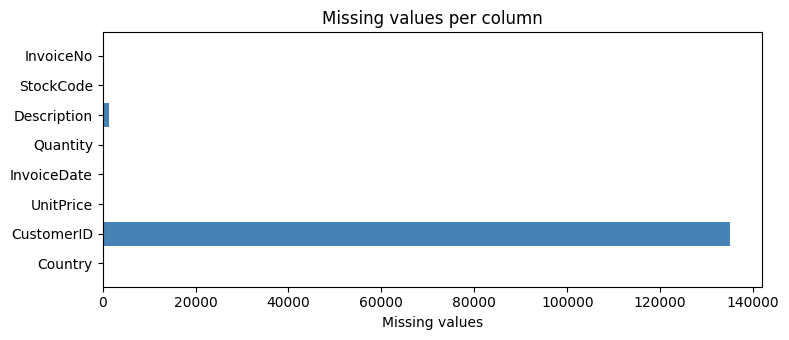

In [ ]:
missing_counts = raw_df.isna().sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(missing_counts.index, missing_counts.values, color="steelblue")
ax.set_xlabel("Missing values")
ax.set_title("Missing values per column")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 6.2 Duplicate rows and invoice structure

In [ ]:
duplicate_mask = raw_df.duplicated(keep=False)
duplicate_row_count = int(raw_df.duplicated().sum())
print("Fully duplicated rows (extra copies):", f"{duplicate_row_count:,}", f"({duplicate_row_count / len(raw_df) * 100:.2f}% of rows)")
raw_df[duplicate_mask].sort_values(["InvoiceNo", "StockCode"]).head(10)

Fully duplicated rows (extra copies): 5,268 (0.97% of rows)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [ ]:
lines_per_invoice = raw_df.groupby(invoice_text).size()
invoice_customers = raw_df.groupby(invoice_text)["CustomerID"].nunique(dropna=False)
invoice_timestamps = raw_df.groupby(invoice_text)["InvoiceDate"].nunique()

invoice_structure = pd.DataFrame(
    {
        "check": [
            "Invoices",
            "Invoices with more than one line (expected, an invoice holds many products)",
            "Invoices linked to more than one CustomerID",
            "Invoices with more than one InvoiceDate value",
        ],
        "count": [len(lines_per_invoice), int((lines_per_invoice > 1).sum()), int((invoice_customers > 1).sum()), int((invoice_timestamps > 1).sum())],
    }
)
invoice_structure

,check,count
0,Invoices,25900
1,"Invoices with more than one line (expected, an...",20059
2,Invoices linked to more than one CustomerID,0
3,Invoices with more than one InvoiceDate value,43


In [ ]:
lines_per_invoice.describe().to_frame("lines_per_invoice")

,lines_per_invoice
count,25900.000000
mean,20.923127
std,43.031334
min,1.000000
25%,2.000000
50%,10.000000
75%,23.000000
max,1114.000000


### 6.3 Quantity and price

In [ ]:
quantity_issues = pd.DataFrame(
    {
        "check": ["Quantity equal to zero", "Quantity below zero", "UnitPrice equal to zero", "UnitPrice below zero"],
        "rows": [
            int((raw_df["Quantity"] == 0).sum()),
            int((raw_df["Quantity"] < 0).sum()),
            int((raw_df["UnitPrice"] == 0).sum()),
            int((raw_df["UnitPrice"] < 0).sum()),
        ],
    }
)
quantity_issues["percent_of_rows"] = (quantity_issues["rows"] / len(raw_df) * 100).round(3)
quantity_issues

,check,rows,percent_of_rows
0,Quantity equal to zero,0,0.000
1,Quantity below zero,10624,1.960
2,UnitPrice equal to zero,2515,0.464
3,UnitPrice below zero,2,0.000


In [ ]:
raw_df[raw_df["Quantity"] < 0].head(8)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom


In [ ]:
raw_df[raw_df["UnitPrice"] <= 0].head(8)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom


In [ ]:
extreme_rows = raw_df[raw_df["Quantity"].abs() >= 10000]
print("Rows with absolute quantity of 10,000 or more:", len(extreme_rows))
extreme_rows

Rows with absolute quantity of 10,000 or more: 5


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


### 6.4 Missing CustomerID and missing descriptions

In [ ]:
missing_customer = raw_df["CustomerID"].isna()
missing_description = raw_df["Description"].isna()
raw_revenue_line = raw_df["Quantity"] * raw_df["UnitPrice"]

customer_issue_table = pd.DataFrame(
    {
        "check": [
            "Rows without CustomerID",
            "Rows without Description",
            "Rows missing both",
            "Rows without Description that have a CustomerID",
            "Unit price zero among rows without Description",
        ],
        "rows": [
            int(missing_customer.sum()),
            int(missing_description.sum()),
            int((missing_customer & missing_description).sum()),
            int((~missing_customer & missing_description).sum()),
            int((missing_description & (raw_df["UnitPrice"] == 0)).sum()),
        ],
    }
)
customer_issue_table

,check,rows
0,Rows without CustomerID,135080
1,Rows without Description,1454
2,Rows missing both,1454
3,Rows without Description that have a CustomerID,0
4,Unit price zero among rows without Description,1454


In [ ]:
anonymous_revenue = raw_revenue_line[missing_customer].sum()
total_raw_revenue = raw_revenue_line.sum()
print("Quantity x UnitPrice on rows without CustomerID:", f"{anonymous_revenue:,.2f}")
print("Share of the raw revenue total                 :", f"{anonymous_revenue / total_raw_revenue * 100:.1f}%")

Quantity x UnitPrice on rows without CustomerID: 1,447,682.12
Share of the raw revenue total                 : 14.9%


### 6.5 Cancelled invoices

In [ ]:
cancelled_mask = invoice_text.str.startswith("C")
adjustment_mask = invoice_text.str.startswith("A")
negative_not_cancelled = (raw_df["Quantity"] < 0) & ~cancelled_mask

cancel_table = pd.DataFrame(
    {
        "check": [
            "Lines on invoices starting with C (cancellations)",
            "Distinct cancelled invoices",
            "Lines on invoices starting with A",
            "Negative quantity lines that are not cancellations",
            "Cancelled lines with a positive quantity",
        ],
        "count": [
            int(cancelled_mask.sum()),
            int(invoice_text[cancelled_mask].nunique()),
            int(adjustment_mask.sum()),
            int(negative_not_cancelled.sum()),
            int((cancelled_mask & (raw_df["Quantity"] > 0)).sum()),
        ],
    }
)
cancel_table

,check,count
0,Lines on invoices starting with C (cancellations),9288
1,Distinct cancelled invoices,3836
2,Lines on invoices starting with A,3
3,Negative quantity lines that are not cancellat...,1336
4,Cancelled lines with a positive quantity,0


In [ ]:
raw_df[cancelled_mask].head(6)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [ ]:
raw_df[adjustment_mask]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


### 6.6 Date format and data types

In [ ]:
date_summary = pd.DataFrame(
    {
        "check": ["dtype", "Missing dates", "Earliest invoice", "Latest invoice", "Distinct calendar days", "Rows with non-zero seconds"],
        "result": [
            str(raw_df["InvoiceDate"].dtype),
            int(raw_df["InvoiceDate"].isna().sum()),
            raw_df["InvoiceDate"].min(),
            raw_df["InvoiceDate"].max(),
            raw_df["InvoiceDate"].dt.normalize().nunique(),
            int((raw_df["InvoiceDate"].dt.second != 0).sum()),
        ],
    }
)
date_summary.astype(str)

,check,result
0,dtype,datetime64[us]
1,Missing dates,0
2,Earliest invoice,2010-12-01 08:26:00
3,Latest invoice,2011-12-09 12:50:00
4,Distinct calendar days,305
5,Rows with non-zero seconds,0


In [ ]:
type_check = pd.DataFrame(
    {
        column: raw_df[column].map(lambda value: type(value).__name__).value_counts()
        for column in ["InvoiceNo", "StockCode", "CustomerID"]
    }
).fillna(0).astype(int)
type_check

,InvoiceNo,StockCode,CustomerID
float,0,0,541909
int,532618,487036,0
str,9291,54873,0


### 6.7 Unexpected values

In [ ]:
product_pattern = stock_text.str.match(r"^\d{5}")
non_product_codes = (
    raw_df[~product_pattern]
    .assign(StockCode=stock_text[~product_pattern])
    .groupby("StockCode")
    .agg(lines=("StockCode", "size"), example_description=("Description", "first"))
    .sort_values("lines", ascending=False)
)
print("Distinct stock codes that do not start with a 5-digit product number:", len(non_product_codes))
non_product_codes.head(15)

Distinct stock codes that do not start with a 5-digit product number: 33


,lines,example_description
StockCode,,
POST,1256,POSTAGE
DOT,710,DOTCOM POSTAGE
M,571,Manual
C2,144,CARRIAGE
D,77,Discount
S,63,SAMPLES
BANK CHARGES,37,Bank Charges
AMAZONFEE,34,AMAZON FEE
CRUK,16,CRUK Commission


In [ ]:
descriptions_per_code = raw_df.groupby(stock_text)["Description"].nunique()
prices_per_code = raw_df.groupby(stock_text)["UnitPrice"].nunique()
countries_per_customer = raw_df.groupby("CustomerID")["Country"].nunique()
description_text = raw_df["Description"].dropna().astype(str)

unexpected_table = pd.DataFrame(
    {
        "check": [
            "StockCodes with more than one description",
            "StockCodes with more than one UnitPrice",
            "Customers appearing under more than one country",
            "Descriptions with leading or trailing spaces",
            "Descriptions that contain lowercase letters",
        ],
        "count": [
            int((descriptions_per_code > 1).sum()),
            int((prices_per_code > 1).sum()),
            int((countries_per_customer > 1).sum()),
            int((description_text != description_text.str.strip()).sum()),
            int(description_text.str.contains(r"[a-z]").sum()),
        ],
    }
)
unexpected_table

,check,count
0,StockCodes with more than one description,650
1,StockCodes with more than one UnitPrice,3603
2,Customers appearing under more than one country,8
3,Descriptions with leading or trailing spaces,113452
4,Descriptions that contain lowercase letters,3036


In [ ]:
raw_df["Country"].value_counts().tail(8).to_frame("lines")

,lines
Country,
European Community,61
RSA,58
Lebanon,45
Lithuania,35
Brazil,32
Czech Republic,30
Bahrain,19
Saudi Arabia,10


### 6.8 Data quality summary

All problem counts in one table.

In [ ]:
quality_summary = pd.DataFrame(
    [
        ("Rows without CustomerID", int(missing_customer.sum())),
        ("Rows without Description", int(missing_description.sum())),
        ("Fully duplicated rows", duplicate_row_count),
        ("Lines on cancelled invoices (prefix C)", int(cancelled_mask.sum())),
        ("Lines with Quantity below zero", int((raw_df["Quantity"] < 0).sum())),
        ("Lines with UnitPrice equal to zero", int((raw_df["UnitPrice"] == 0).sum())),
        ("Lines with UnitPrice below zero", int((raw_df["UnitPrice"] < 0).sum())),
        ("Lines with a non-product StockCode", int((~product_pattern).sum())),
    ],
    columns=["issue", "rows"],
)
quality_summary["percent_of_rows"] = (quality_summary["rows"] / len(raw_df) * 100).round(2)
quality_summary.sort_values("rows", ascending=False).reset_index(drop=True)

,issue,rows,percent_of_rows
0,Rows without CustomerID,135080,24.93
1,Lines with Quantity below zero,10624,1.96
2,Lines on cancelled invoices (prefix C),9288,1.71
3,Fully duplicated rows,5268,0.97
4,Lines with a non-product StockCode,2995,0.55
5,Lines with UnitPrice equal to zero,2515,0.46
6,Rows without Description,1454,0.27
7,Lines with UnitPrice below zero,2,0.00


## Section 7: Initial Exploratory Analysis

Charts use the raw data. Rankings only use positive quantities. Revenue = Quantity x UnitPrice, not saved in `raw_df`.

In [ ]:
transactions_by_country = (
    raw_df.assign(invoice=invoice_text)
    .groupby("Country")
    .agg(invoices=("invoice", "nunique"), lines=("invoice", "size"))
    .sort_values("invoices", ascending=False)
)
transactions_by_country.head(10)

,invoices,lines
Country,,
United Kingdom,23494,495478
Germany,603,9495
France,461,8557
EIRE,360,8196
Belgium,119,2069
Spain,105,2533
Netherlands,101,2371
Switzerland,74,2002
Portugal,71,1519


In [ ]:
fig = px.bar(
    transactions_by_country.head(10).reset_index(),
    x="Country",
    y="invoices",
    title="Top 10 countries by number of invoices",
    labels={"invoices": "Invoices"},
)
fig.show()

In [ ]:
customers_by_country = (
    raw_df.dropna(subset=["CustomerID"])
    .groupby("Country")["CustomerID"]
    .nunique()
    .sort_values(ascending=False)
    .rename("customers")
)
fig = px.bar(
    customers_by_country.head(10).reset_index(),
    x="Country",
    y="customers",
    title="Top 10 countries by number of identified customers",
)
fig.show()

In [ ]:
positive_lines = raw_df[raw_df["Quantity"] > 0].assign(StockCode=stock_text)

top_products_quantity = (
    positive_lines.groupby("StockCode")
    .agg(description=("Description", "first"), total_quantity=("Quantity", "sum"))
    .sort_values("total_quantity", ascending=False)
    .head(10)
    .reset_index()
)
top_products_quantity

,StockCode,description,total_quantity
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,22197,SMALL POPCORN HOLDER,56921
3,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047
4,85099B,JUMBO BAG RED RETROSPOT,48478
5,85123A,WHITE HANGING HEART T-LIGHT HOLDER,41664
6,84879,ASSORTED COLOUR BIRD ORNAMENT,36461
7,21212,PACK OF 72 RETROSPOT CAKE CASES,36419
8,23084,RABBIT NIGHT LIGHT,31722
9,22492,MINI PAINT SET VINTAGE,26633


In [ ]:
fig = px.bar(
    top_products_quantity.sort_values("total_quantity"),
    x="total_quantity",
    y="description",
    orientation="h",
    title="Top 10 products by quantity sold (raw data)",
)
fig.show()

In [ ]:
top_products_frequency = (
    positive_lines.assign(invoice=invoice_text)
    .groupby("StockCode")
    .agg(description=("Description", "first"), invoices_containing_product=("invoice", "nunique"))
    .sort_values("invoices_containing_product", ascending=False)
    .head(10)
    .reset_index()
)
top_products_frequency

,StockCode,description,invoices_containing_product
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2203
1,85099B,JUMBO BAG RED RETROSPOT,2092
2,22423,REGENCY CAKESTAND 3 TIER,1989
3,47566,PARTY BUNTING,1686
4,20725,LUNCH BAG RED RETROSPOT,1565
5,84879,ASSORTED COLOUR BIRD ORNAMENT,1455
6,22197,SMALL POPCORN HOLDER,1392
7,22720,SET OF 3 CAKE TINS PANTRY DESIGN,1387
8,21212,PACK OF 72 RETROSPOT CAKE CASES,1320
9,22383,LUNCH BAG SUKI DESIGN,1285


In [ ]:
revenue_overview = pd.DataFrame(
    {
        "measure": [
            "Sum of Quantity x UnitPrice, all rows",
            "Sum for rows with positive quantity",
            "Sum for rows with negative quantity",
            "Sum for rows without CustomerID",
        ],
        "value": [
            raw_revenue_line.sum(),
            raw_revenue_line[raw_df["Quantity"] > 0].sum(),
            raw_revenue_line[raw_df["Quantity"] < 0].sum(),
            raw_revenue_line[missing_customer].sum(),
        ],
    }
)
revenue_overview["value"] = revenue_overview["value"].map("{:,.2f}".format)
revenue_overview

,measure,value
0,"Sum of Quantity x UnitPrice, all rows","9,747,747.93"
1,Sum for rows with positive quantity,"10,644,560.42"
2,Sum for rows with negative quantity,"-896,812.49"
3,Sum for rows without CustomerID,"1,447,682.12"


In [ ]:
monthly_volume = (
    raw_df.assign(month=raw_df["InvoiceDate"].dt.to_period("M").astype(str), invoice=invoice_text)
    .groupby("month")
    .agg(invoices=("invoice", "nunique"), lines=("invoice", "size"))
    .reset_index()
)
monthly_volume

,month,invoices,lines
0,2010-12,2025,42481
1,2011-01,1476,35147
2,2011-02,1393,27707
3,2011-03,1983,36748
4,2011-04,1744,29916
5,2011-05,2162,37030
6,2011-06,2012,36874
7,2011-07,1927,39518
8,2011-08,1737,35284
9,2011-09,2327,50226


In [ ]:
fig = px.line(
    monthly_volume,
    x="month",
    y="invoices",
    markers=True,
    title="Monthly transaction volume (unique invoices, raw data)",
)
fig.show()

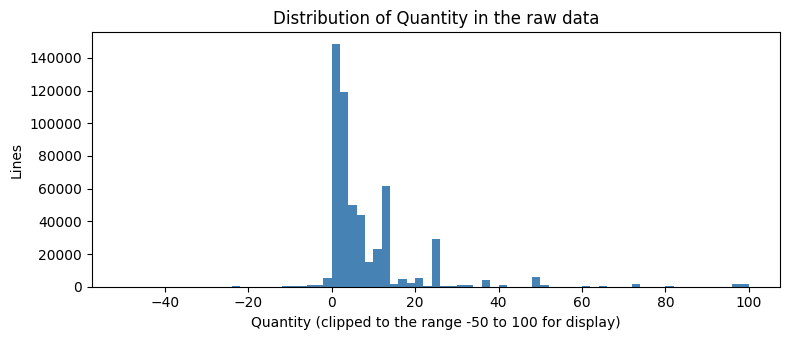

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(raw_df.loc[raw_df["Quantity"].between(-50, 100), "Quantity"], bins=75, color="steelblue")
ax.set_xlabel("Quantity (clipped to the range -50 to 100 for display)")
ax.set_ylabel("Lines")
ax.set_title("Distribution of Quantity in the raw data")
plt.tight_layout()
plt.show()

## Section 8: Initial Findings

Numbers below come from the code above.

In [ ]:
from IPython.display import Markdown, display

top_country = transactions_by_country.index[0]
top_country_share = transactions_by_country["invoices"].iloc[0] / transactions_by_country["invoices"].sum() * 100
busiest_month = monthly_volume.loc[monthly_volume["invoices"].idxmax()]
complete_months = monthly_volume.iloc[:-1]
quietest_month = complete_months.loc[complete_months["invoices"].idxmin()]
partial_month = monthly_volume.iloc[-1]

findings = f"""
**Dataset obtained.** `{excel_path.name}` was extracted from `{zip_path.name}` and loaded into `raw_df` with {len(raw_df):,} rows and {raw_df.shape[1]} columns, covering {raw_df['InvoiceDate'].min():%d %B %Y} to {raw_df['InvoiceDate'].max():%d %B %Y}.

**Scale.** The data holds {invoice_text.nunique():,} invoices, {raw_df['CustomerID'].nunique():,} identified customers, {stock_text.nunique():,} stock codes and {raw_df['Country'].nunique()} countries.

**Data quality problems discovered**

- {int(missing_customer.sum()):,} rows ({missing_customer.mean() * 100:.1f}%) have no CustomerID, and {int(missing_description.sum()):,} rows have no Description.
- {duplicate_row_count:,} rows are exact duplicates of another row.
- {int(cancelled_mask.sum()):,} lines belong to cancelled invoices, and {int((raw_df['Quantity'] < 0).sum()):,} lines in total have a negative quantity.
- {int((raw_df['UnitPrice'] <= 0).sum()):,} lines have a zero or negative unit price.
- {int((~product_pattern).sum()):,} lines use stock codes that are not product numbers, such as postage and manual adjustments.
- InvoiceNo and StockCode contain a mix of numbers and text, and {int((descriptions_per_code > 1).sum()):,} stock codes have more than one description.

**Patterns discovered**

- {top_country} accounts for {top_country_share:.1f}% of all invoices.
- Monthly invoice volume is highest in {busiest_month['month']} ({int(busiest_month['invoices']):,} invoices) and lowest among complete months in {quietest_month['month']} ({int(quietest_month['invoices']):,} invoices). The final month, {partial_month['month']}, is incomplete because the data ends on {raw_df['InvoiceDate'].max():%d %B %Y}.
- Quantity contains extreme positive and negative values that need inspection before any analysis.
"""
display(Markdown(findings))


**Dataset obtained.** `Online Retail.xlsx` was extracted from `online+retail.zip` and loaded into `raw_df` with 541,909 rows and 8 columns, covering 01 December 2010 to 09 December 2011.

**Scale.** The data holds 25,900 invoices, 4,372 identified customers, 4,070 stock codes and 38 countries.

**Data quality problems discovered**

- 135,080 rows (24.9%) have no CustomerID, and 1,454 rows have no Description.
- 5,268 rows are exact duplicates of another row.
- 9,288 lines belong to cancelled invoices, and 10,624 lines in total have a negative quantity.
- 2,517 lines have a zero or negative unit price.
- 2,995 lines use stock codes that are not product numbers, such as postage and manual adjustments.
- InvoiceNo and StockCode contain a mix of numbers and text, and 650 stock codes have more than one description.

**Patterns discovered**

- United Kingdom accounts for 90.7% of all invoices.
- Monthly invoice volume is highest in 2011-11 (3,462 invoices) and lowest among complete months in 2011-02 (1,393 invoices). The final month, 2011-12, is incomplete because the data ends on 09 December 2011.
- Quantity contains extreme positive and negative values that need inspection before any analysis.


# Cleaning and Transformation

Fix the problems found during exploration. `raw_df` stays as it is. All cleaning is done on `clean_df`.

## Section 1: Start From the Raw Data

`clean_df` is a copy of `raw_df`.

In [ ]:
pd.set_option("display.float_format", "{:,.2f}".format)

In [ ]:
clean_df = raw_df.copy()
print("raw_df rows  :", f"{len(raw_df):,}")
print("clean_df rows:", f"{len(clean_df):,}")

raw_df rows  : 541,909
clean_df rows: 541,909


## Section 2: Data Cleaning

Helper removes rows, prints before/after counts and logs each step.

In [ ]:
cleaning_log = []


def remove_rows(frame, remove_mask, step, reason):
    before_rows = len(frame)
    removed = frame[remove_mask]
    kept = frame[~remove_mask]
    cleaning_log.append(
        {"step": step, "before_rows": before_rows, "rows_removed": len(removed), "after_rows": len(kept), "reason": reason}
    )
    print(f"{step}")
    print(f"  Before rows : {before_rows:,}")
    print(f"  Rows removed: {len(removed):,}")
    print(f"  After rows  : {len(kept):,}")
    return kept, removed

### 2.1 Convert data types and standardize text

InvoiceNo and StockCode become text. Trim text and make description and stock code upper case, so one product has one spelling.

In [ ]:
dtypes_before = clean_df.dtypes.astype(str).rename("dtype_before")
descriptions_before = clean_df["Description"].copy()
stock_before = clean_df["StockCode"].astype(str).copy()

clean_df["InvoiceNo"] = clean_df["InvoiceNo"].astype(str).str.strip()
clean_df["StockCode"] = clean_df["StockCode"].astype(str).str.strip().str.upper()
clean_df["Description"] = (
    clean_df["Description"].str.upper().str.replace(r"\s+", " ", regex=True).str.strip()
)
clean_df["Country"] = clean_df["Country"].str.strip()
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"], errors="coerce")
clean_df["Quantity"] = pd.to_numeric(clean_df["Quantity"], errors="coerce")
clean_df["UnitPrice"] = pd.to_numeric(clean_df["UnitPrice"], errors="coerce")

dtypes_after = clean_df.dtypes.astype(str).rename("dtype_after")
pd.concat([dtypes_before, dtypes_after], axis=1)

,dtype_before,dtype_after
InvoiceNo,object,str
StockCode,object,str
Description,object,object
Quantity,int64,int64
InvoiceDate,datetime64[us],datetime64[us]
UnitPrice,float64,float64
CustomerID,float64,float64
Country,str,str


In [ ]:
conversion_checks = pd.DataFrame(
    {
        "check": [
            "Dates that could not be parsed",
            "Quantities that could not be parsed",
            "Unit prices that could not be parsed",
            "Descriptions changed by standardization",
            "StockCodes changed by standardization",
        ],
        "count": [
            int(clean_df["InvoiceDate"].isna().sum()),
            int(clean_df["Quantity"].isna().sum()),
            int(clean_df["UnitPrice"].isna().sum()),
            int((descriptions_before.fillna("") != clean_df["Description"].fillna("")).sum()),
            int((stock_before != clean_df["StockCode"]).sum()),
        ],
    }
)
conversion_checks

,check,count
0,Dates that could not be parsed,0
1,Quantities that could not be parsed,0
2,Unit prices that could not be parsed,0
3,Descriptions changed by standardization,131126
4,StockCodes changed by standardization,1977


In [ ]:
changed_descriptions = descriptions_before.fillna("") != clean_df["Description"].fillna("")
pd.DataFrame(
    {"before": descriptions_before[changed_descriptions], "after": clean_df.loc[changed_descriptions, "Description"]}
).head(8)

,before,after
10,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE BEDROOM
13,IVORY KNITTED MUG COSY,IVORY KNITTED MUG COSY
15,BOX OF VINTAGE JIGSAW BLOCKS,BOX OF VINTAGE JIGSAW BLOCKS
27,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE RED
30,STARS GIFT TAPE,STARS GIFT TAPE
31,INFLATABLE POLITICAL GLOBE,INFLATABLE POLITICAL GLOBE
32,VINTAGE HEADS AND TAILS CARD GAME,VINTAGE HEADS AND TAILS CARD GAME
33,SET/2 RED RETROSPOT TEA TOWELS,SET/2 RED RETROSPOT TEA TOWELS


### 2.2 Remove duplicate records

Drop identical rows, keep the first. Count can be higher than the raw count because cleaning the text exposes more duplicates.

In [ ]:
raw_duplicates = int(raw_df.duplicated().sum())
clean_df, removed_duplicates = remove_rows(
    clean_df, clean_df.duplicated(keep="first"), "Remove duplicate rows", "Identical rows repeat the same sale"
)
print("  Exact duplicates found in the raw data:", f"{raw_duplicates:,}")
removed_duplicates.head()

Remove duplicate rows
  Before rows : 541,909
  Rows removed: 5,268
  After rows  : 536,641
  Exact duplicates found in the raw data: 5,268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,"17,908.00",United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,"17,920.00",United Kingdom


### 2.3 Separate cancelled invoices

Invoices starting with C are cancellations. Move them to `cancelled_df`.

In [ ]:
cancel_mask = clean_df["InvoiceNo"].str.startswith("C")
clean_df, cancelled_df = remove_rows(
    clean_df, cancel_mask, "Separate cancelled invoices", "Cancellations are not sales and carry negative quantities"
)
cancelled_df = cancelled_df.assign(Revenue=(cancelled_df["Quantity"] * cancelled_df["UnitPrice"]).round(2))
cancelled_df.head()

Separate cancelled invoices
  Before rows : 536,641
  Rows removed: 9,251
  After rows  : 527,390


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
141,C536379,D,DISCOUNT,-1,2010-12-01 09:41:00,27.50,"14,527.00",United Kingdom,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,"15,311.00",United Kingdom,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom,-6.96


### 2.4 Remove invalid quantities

In [ ]:
clean_df, invalid_quantity = remove_rows(
    clean_df, clean_df["Quantity"] <= 0, "Remove zero or negative quantities", "Sales must have a positive quantity"
)
invalid_quantity.head()

Remove zero or negative quantities
  Before rows : 527,390
  Rows removed: 1,336
  After rows  : 526,054


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.00,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.00,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.00,NaN,United Kingdom


### 2.5 Remove invalid prices

In [ ]:
clean_df, invalid_price = remove_rows(
    clean_df, clean_df["UnitPrice"] <= 0, "Remove zero or negative prices", "A sale must have a positive price"
)
invalid_price.head()

Remove zero or negative prices
  Before rows : 526,054
  Rows removed: 1,176
  After rows  : 524,878


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.00,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom


### 2.6 Remove non-product stock codes

POST, M, BANK CHARGES etc. are not products. Product codes start with 5 digits, drop the rest.

In [ ]:
non_product_mask = ~clean_df["StockCode"].str.match(r"^\d{5}")
non_product_summary = (
    clean_df[non_product_mask].groupby("StockCode").agg(lines=("StockCode", "size"), example=("Description", "first")).sort_values("lines", ascending=False)
)
non_product_summary

,lines,example
StockCode,,
POST,1126,POSTAGE
DOT,706,DOTCOM POSTAGE
M,317,MANUAL
C2,141,CARRIAGE
DCGSSGIRL,13,GIRLS PARTY BAG
BANK CHARGES,12,BANK CHARGES
DCGSSBOY,11,BOYS PARTY BAG
GIFT_0001_20,9,DOTCOMGIFTSHOP GIFT VOUCHER £20.00
GIFT_0001_10,8,DOTCOMGIFTSHOP GIFT VOUCHER £10.00


In [ ]:
clean_df, non_product_rows = remove_rows(
    clean_df, non_product_mask, "Remove non-product stock codes", "Postage, fees and manual entries are not products"
)

Remove non-product stock codes
  Before rows : 524,878
  Rows removed: 2,374
  After rows  : 522,504


### 2.7 Handle missing CustomerID

Orders need a customer, so rows with no CustomerID are dropped. Biggest loss of rows.

In [ ]:
clean_df, missing_customer_rows = remove_rows(
    clean_df,
    clean_df["CustomerID"].isna(),
    "Remove rows without CustomerID",
    "Orders must reference a customer in the relational model",
)
missing_customer_rows.head()

Remove rows without CustomerID
  Before rows : 522,504
  Rows removed: 131,354
  After rows  : 391,150


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom


In [ ]:
clean_df["CustomerID"] = clean_df["CustomerID"].astype("int64")
clean_df["CustomerID"].dtype

dtype('int64')

### 2.7b Remove sales that were fully reversed

Some big orders were cancelled right after. Match each cancellation to an earlier sale (same customer, product, quantity) and drop that sale. Partial returns are not matched.

In [ ]:
sale_keys = clean_df[["CustomerID", "StockCode", "Quantity", "InvoiceDate"]].copy()
sale_keys["row_id"] = sale_keys.index
sale_keys = sale_keys.sort_values(["InvoiceDate", "row_id"])
sale_keys["occurrence"] = sale_keys.groupby(["CustomerID", "StockCode", "Quantity"]).cumcount()

cancel_keys = cancelled_df.dropna(subset=["CustomerID"]).copy()
cancel_keys["CustomerID"] = cancel_keys["CustomerID"].astype("int64")
cancel_keys["Quantity"] = -cancel_keys["Quantity"]
cancel_keys = cancel_keys.sort_values("InvoiceDate")
cancel_keys["occurrence"] = cancel_keys.groupby(["CustomerID", "StockCode", "Quantity"]).cumcount()
cancel_keys = cancel_keys.rename(columns={"InvoiceDate": "cancel_date"})

matched_pairs = sale_keys.merge(
    cancel_keys[["CustomerID", "StockCode", "Quantity", "occurrence", "cancel_date"]],
    on=["CustomerID", "StockCode", "Quantity", "occurrence"],
    how="inner",
)
matched_pairs = matched_pairs[matched_pairs["InvoiceDate"] <= matched_pairs["cancel_date"]]
print("Cancelled lines available for matching:", f"{len(cancel_keys):,}")
print("Cancelled lines matched to an earlier sale:", f"{len(matched_pairs):,}")
matched_pairs.sort_values("Quantity", ascending=False).head(5)

Cancelled lines available for matching: 8,872
Cancelled lines matched to an earlier sale: 2,797


,CustomerID,StockCode,Quantity,InvoiceDate,row_id,occurrence,cancel_date
3081,16446,23843,80995,2011-12-09 09:15:00,540421,0,2011-12-09 09:27:00
452,12346,23166,74215,2011-01-18 10:01:00,61619,0,2011-01-18 10:17:00
387,15749,21108,3114,2011-01-11 12:55:00,52711,0,2011-04-18 13:08:00
386,15749,21175,2000,2011-01-11 12:55:00,52710,0,2011-04-18 13:08:00
385,15749,85123A,1930,2011-01-11 12:55:00,52709,0,2011-04-18 13:08:00


In [ ]:
clean_df, reversed_sales_df = remove_rows(
    clean_df,
    clean_df.index.isin(matched_pairs["row_id"]),
    "Remove sales fully reversed by a cancellation",
    "A sale cancelled in full has no net revenue",
)
reversed_sales_df = reversed_sales_df.assign(Revenue=(reversed_sales_df["Quantity"] * reversed_sales_df["UnitPrice"]).round(2))
reversed_sales_df.sort_values("Revenue", ascending=False).head()

Remove sales fully reversed by a cancellation
  Before rows : 391,150
  Rows removed: 2,797
  After rows  : 388,353


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,"168,469.60"
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,"77,183.60"
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10,15749,United Kingdom,"6,539.40"
52709,540815,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2011-01-11 12:55:00,2.55,15749,United Kingdom,"4,921.50"
52772,540818,48185,DOORMAT FAIRY CAKE,670,2011-01-11 12:57:00,6.75,15749,United Kingdom,"4,522.50"


### 2.8 Handle missing descriptions

Fill from the same stock code. Drop any that are still missing.

In [ ]:
missing_before = int(clean_df["Description"].isna().sum())
known_descriptions = clean_df.dropna(subset=["Description"]).groupby("StockCode")["Description"].agg(lambda s: s.value_counts().index[0])
clean_df["Description"] = clean_df["Description"].fillna(clean_df["StockCode"].map(known_descriptions))
missing_after_fill = int(clean_df["Description"].isna().sum())
print("Missing descriptions before filling:", missing_before)
print("Missing descriptions after filling :", missing_after_fill)

Missing descriptions before filling: 0
Missing descriptions after filling : 0


In [ ]:
clean_df, missing_description_rows = remove_rows(
    clean_df, clean_df["Description"].isna(), "Remove rows with unrecoverable description", "No product name is available"
)

Remove rows with unrecoverable description
  Before rows : 388,353
  Rows removed: 0
  After rows  : 388,353


## Section 3: Cleaning Progress

In [ ]:
cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df.loc[len(cleaning_log_df)] = {
    "step": "Total",
    "before_rows": len(raw_df),
    "rows_removed": len(raw_df) - len(clean_df),
    "after_rows": len(clean_df),
    "reason": "Raw rows compared with rows kept",
}
cleaning_log_df

,step,before_rows,rows_removed,after_rows,reason
0,Remove duplicate rows,541909,5268,536641,Identical rows repeat the same sale
1,Separate cancelled invoices,536641,9251,527390,Cancellations are not sales and carry negative...
2,Remove zero or negative quantities,527390,1336,526054,Sales must have a positive quantity
3,Remove zero or negative prices,526054,1176,524878,A sale must have a positive price
4,Remove non-product stock codes,524878,2374,522504,"Postage, fees and manual entries are not products"
5,Remove rows without CustomerID,522504,131354,391150,Orders must reference a customer in the relati...
6,Remove sales fully reversed by a cancellation,391150,2797,388353,A sale cancelled in full has no net revenue
7,Remove rows with unrecoverable description,388353,0,388353,No product name is available
8,Total,541909,153556,388353,Raw rows compared with rows kept


In [ ]:
steps_only = cleaning_log_df[cleaning_log_df["step"] != "Total"]
fig = px.bar(
    steps_only,
    x="step",
    y="rows_removed",
    title="Rows removed at each cleaning step",
    labels={"rows_removed": "Rows removed", "step": "Cleaning step"},
)
fig.show()

In [ ]:
comparison = pd.DataFrame(
    {
        "measure": ["Rows", "Invoices", "Customers", "Stock codes", "Countries"],
        "raw_df": [
            len(raw_df),
            raw_df["InvoiceNo"].astype(str).nunique(),
            raw_df["CustomerID"].nunique(),
            raw_df["StockCode"].astype(str).nunique(),
            raw_df["Country"].nunique(),
        ],
        "clean_df": [
            len(clean_df),
            clean_df["InvoiceNo"].nunique(),
            clean_df["CustomerID"].nunique(),
            clean_df["StockCode"].nunique(),
            clean_df["Country"].nunique(),
        ],
    }
)
comparison["retained_percent"] = (comparison["clean_df"] / comparison["raw_df"] * 100).round(1)
comparison

,measure,raw_df,clean_df,retained_percent
0,Rows,541909,388353,71.70
1,Invoices,25900,18325,70.80
2,Customers,4372,4324,98.90
3,Stock codes,4070,3646,89.60
4,Countries,38,37,97.40


In [ ]:
issue_recheck = pd.DataFrame(
    {
        "check": [
            "Missing values (all columns)",
            "Duplicate rows",
            "Quantity of zero or below",
            "UnitPrice of zero or below",
            "InvoiceNo starting with C",
            "StockCode not starting with a 5-digit number",
        ],
        "raw_df": [
            int(raw_df.isna().sum().sum()),
            int(raw_df.duplicated().sum()),
            int((raw_df["Quantity"] <= 0).sum()),
            int((raw_df["UnitPrice"] <= 0).sum()),
            int(raw_df["InvoiceNo"].astype(str).str.startswith("C").sum()),
            int((~raw_df["StockCode"].astype(str).str.match(r"^\d{5}")).sum()),
        ],
        "clean_df": [
            int(clean_df.isna().sum().sum()),
            int(clean_df.duplicated().sum()),
            int((clean_df["Quantity"] <= 0).sum()),
            int((clean_df["UnitPrice"] <= 0).sum()),
            int(clean_df["InvoiceNo"].str.startswith("C").sum()),
            int((~clean_df["StockCode"].str.match(r"^\d{5}")).sum()),
        ],
    }
)
issue_recheck

,check,raw_df,clean_df
0,Missing values (all columns),136534,0
1,Duplicate rows,5268,0
2,Quantity of zero or below,10624,0
3,UnitPrice of zero or below,2517,0
4,InvoiceNo starting with C,9288,0
5,StockCode not starting with a 5-digit number,2995,0


In [ ]:
print("raw_df still has its original shape:", raw_df.shape)
print("Cancelled invoices stored separately:", f"{len(cancelled_df):,}", "lines")
clean_df.head()

raw_df still has its original shape: (541909, 8)
Cancelled invoices stored separately: 9,251 lines


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## Section 4: Feature Engineering

Revenue = Quantity x UnitPrice. Add year, month, day, weekday and hour fields.

In [ ]:
clean_df["Revenue"] = (clean_df["Quantity"] * clean_df["UnitPrice"]).round(2)
clean_df["Year"] = clean_df["InvoiceDate"].dt.year
clean_df["Month"] = clean_df["InvoiceDate"].dt.month
clean_df["MonthName"] = clean_df["InvoiceDate"].dt.month_name()
clean_df["Day"] = clean_df["InvoiceDate"].dt.day
clean_df["Weekday"] = clean_df["InvoiceDate"].dt.day_name()
clean_df["Hour"] = clean_df["InvoiceDate"].dt.hour
clean_df["YearMonth"] = clean_df["InvoiceDate"].dt.strftime("%Y-%m")
clean_df[["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "Revenue", "Year", "Month", "MonthName", "Day", "Weekday", "Hour", "YearMonth"]].head(10)

,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Revenue,Year,Month,MonthName,Day,Weekday,Hour,YearMonth
0,536365,2010-12-01 08:26:00,6,2.55,15.30,2010,12,December,1,Wednesday,8,2010-12
1,536365,2010-12-01 08:26:00,6,3.39,20.34,2010,12,December,1,Wednesday,8,2010-12
2,536365,2010-12-01 08:26:00,8,2.75,22.00,2010,12,December,1,Wednesday,8,2010-12
3,536365,2010-12-01 08:26:00,6,3.39,20.34,2010,12,December,1,Wednesday,8,2010-12
4,536365,2010-12-01 08:26:00,6,3.39,20.34,2010,12,December,1,Wednesday,8,2010-12
5,536365,2010-12-01 08:26:00,2,7.65,15.30,2010,12,December,1,Wednesday,8,2010-12
6,536365,2010-12-01 08:26:00,6,4.25,25.50,2010,12,December,1,Wednesday,8,2010-12
7,536366,2010-12-01 08:28:00,6,1.85,11.10,2010,12,December,1,Wednesday,8,2010-12
9,536367,2010-12-01 08:34:00,32,1.69,54.08,2010,12,December,1,Wednesday,8,2010-12
10,536367,2010-12-01 08:34:00,6,2.10,12.60,2010,12,December,1,Wednesday,8,2010-12


In [ ]:
print("Columns before feature engineering:", len(raw_df.columns))
print("Columns after feature engineering :", len(clean_df.columns))
print("Total revenue in clean_df:", f"{clean_df['Revenue'].sum():,.2f}")
clean_df[["Quantity", "UnitPrice", "Revenue"]].describe()

Columns before feature engineering: 8
Columns after feature engineering : 16
Total revenue in clean_df: 8,349,645.02


,Quantity,UnitPrice,Revenue
count,"388,353.00","388,353.00","388,353.00"
mean,12.66,2.86,21.50
std,42.18,4.12,92.67
min,1.00,0.04,0.06
25%,2.00,1.25,4.95
50%,6.00,1.95,11.90
75%,12.00,3.75,19.80
max,"4,800.00",649.50,"38,970.00"


In [ ]:
clean_df.groupby("YearMonth")["Revenue"].sum().round(2).to_frame("revenue")

,revenue
YearMonth,
2010-12,"554,230.92"
2011-01,"454,888.11"
2011-02,"438,390.02"
2011-03,"573,294.62"
2011-04,"450,140.05"
2011-05,"652,185.47"
2011-06,"644,183.90"
2011-07,"582,273.78"
2011-08,"630,531.59"


## Section 5: Relational Data Preparation

Split the clean data into 4 DataFrames: customers, products, orders and order details.

| DataFrame | Meaning | Primary key |
|---|---|---|
| `customers_df` | One row per customer | `customer_id` |
| `products_df` | One row per stock code | `product_id` |
| `orders_df` | One row per invoice | `order_id` |
| `order_details_df` | One row per invoice line | `order_detail_id` |

`customer_id` and `order_id` come from the data. `product_id` and `order_detail_id` are numbered after sorting, so they are the same every run.

### 5.1 customers_df

In [ ]:
country_counts = (
    clean_df.groupby(["CustomerID", "Country"]).size().reset_index(name="lines")
    .sort_values(["CustomerID", "lines", "Country"], ascending=[True, False, True])
)
customers_with_several_countries = int((country_counts.groupby("CustomerID").size() > 1).sum())

customers_df = (
    country_counts.drop_duplicates("CustomerID")[["CustomerID", "Country"]]
    .rename(columns={"CustomerID": "customer_id", "Country": "country"})
    .reset_index(drop=True)
)
print("Customers with lines under more than one country:", customers_with_several_countries, "(most frequent country is kept)")
print("customers_df shape:", customers_df.shape)
customers_df.head()

Customers with lines under more than one country: 8 (most frequent country is kept)
customers_df shape: (4324, 2)


,customer_id,country
0,12347,Iceland
1,12348,Finland
2,12349,Italy
3,12350,Norway
4,12352,Norway


### 5.2 products_df

A stock code can have many descriptions and prices. Use the most common description and the median price.

In [ ]:
description_counts = (
    clean_df.groupby(["StockCode", "Description"]).size().reset_index(name="lines")
    .sort_values(["StockCode", "lines", "Description"], ascending=[True, False, True])
    .drop_duplicates("StockCode")[["StockCode", "Description"]]
)
median_price = clean_df.groupby("StockCode")["UnitPrice"].median().round(2).rename("unit_price").reset_index()

products_df = description_counts.merge(median_price, on="StockCode").sort_values("StockCode").reset_index(drop=True)
products_df.insert(0, "product_id", range(1, len(products_df) + 1))
products_df = products_df.rename(columns={"StockCode": "stock_code", "Description": "description"})
print("products_df shape:", products_df.shape)
products_df.head()

products_df shape: (3646, 4)


,product_id,stock_code,description,unit_price
0,1,10002,INFLATABLE POLITICAL GLOBE,0.85
1,2,10080,GROOVY CACTUS INFLATABLE,0.39
2,3,10120,DOGGY RUBBER,0.21
3,4,10123C,HEARTS WRAPPING TAPE,0.65
4,5,10124A,SPOTS ON RED BOOKCOVER TAPE,0.42


### 5.3 orders_df

In [ ]:
invoice_checks = clean_df.groupby("InvoiceNo").agg(customers=("CustomerID", "nunique"), timestamps=("InvoiceDate", "nunique"))
print("Invoices with more than one customer :", int((invoice_checks["customers"] > 1).sum()))
print("Invoices with more than one timestamp:", int((invoice_checks["timestamps"] > 1).sum()), "(the earliest timestamp is used)")
print("All invoice numbers are numeric       :", bool(clean_df["InvoiceNo"].str.isdigit().all()))

Invoices with more than one customer : 0
Invoices with more than one timestamp: 30 (the earliest timestamp is used)
All invoice numbers are numeric       : True


In [ ]:
orders_df = (
    clean_df.groupby("InvoiceNo")
    .agg(customer_id=("CustomerID", "first"), order_date=("InvoiceDate", "min"))
    .reset_index()
)
orders_df["order_id"] = orders_df["InvoiceNo"].astype("int64")
orders_df = orders_df[["order_id", "customer_id", "order_date"]].sort_values("order_id").reset_index(drop=True)
print("orders_df shape:", orders_df.shape)
orders_df.head()

orders_df shape: (18325, 3)


,order_id,customer_id,order_date
0,536365,17850,2010-12-01 08:26:00
1,536366,17850,2010-12-01 08:28:00
2,536367,13047,2010-12-01 08:34:00
3,536368,13047,2010-12-01 08:34:00
4,536369,13047,2010-12-01 08:35:00


### 5.4 order_details_df

In [ ]:
product_lookup = products_df.set_index("stock_code")["product_id"]
sorted_lines = clean_df.sort_values(
    ["InvoiceDate", "InvoiceNo", "StockCode", "Quantity", "UnitPrice"], kind="stable"
).reset_index(drop=True)

order_details_df = pd.DataFrame(
    {
        "order_detail_id": np.arange(1, len(sorted_lines) + 1),
        "order_id": sorted_lines["InvoiceNo"].astype("int64"),
        "product_id": sorted_lines["StockCode"].map(product_lookup).astype("int64"),
        "quantity": sorted_lines["Quantity"].astype("int64"),
        "unit_price": sorted_lines["UnitPrice"].astype("float64"),
        "revenue": sorted_lines["Revenue"].astype("float64"),
    }
)
print("order_details_df shape:", order_details_df.shape)
order_details_df.head()

order_details_df shape: (388353, 6)


,order_detail_id,order_id,product_id,quantity,unit_price,revenue
0,1,536365,750,6,4.25,25.50
1,2,536365,1600,2,7.65,15.30
2,3,536365,2641,6,3.39,20.34
3,4,536365,2792,6,3.39,20.34
4,5,536365,2793,6,3.39,20.34


In [ ]:
pd.DataFrame(
    {
        "dataframe": ["customers_df", "products_df", "orders_df", "order_details_df"],
        "rows": [len(customers_df), len(products_df), len(orders_df), len(order_details_df)],
        "columns": [", ".join(frame.columns) for frame in [customers_df, products_df, orders_df, order_details_df]],
    }
)

,dataframe,rows,columns
0,customers_df,4324,"customer_id, country"
1,products_df,3646,"product_id, stock_code, description, unit_price"
2,orders_df,18325,"order_id, customer_id, order_date"
3,order_details_df,388353,"order_detail_id, order_id, product_id, quantit..."


## Section 6: Data Validation

Each check gives PASS or FAIL. Stops if anything fails.

In [ ]:
validation_results = []


def record_check(area, check, passed, detail):
    validation_results.append({"area": area, "check": check, "result": "PASS" if passed else "FAIL", "detail": detail})


record_check("Primary key", "customers_df.customer_id is unique", customers_df["customer_id"].is_unique, f"{len(customers_df):,} rows")
record_check("Primary key", "products_df.product_id is unique", products_df["product_id"].is_unique, f"{len(products_df):,} rows")
record_check("Primary key", "products_df.stock_code is unique", products_df["stock_code"].is_unique, f"{len(products_df):,} rows")
record_check("Primary key", "orders_df.order_id is unique", orders_df["order_id"].is_unique, f"{len(orders_df):,} rows")
record_check("Primary key", "order_details_df.order_detail_id is unique", order_details_df["order_detail_id"].is_unique, f"{len(order_details_df):,} rows")

orphan_orders_customer = int((~orders_df["customer_id"].isin(customers_df["customer_id"])).sum())
orphan_details_order = int((~order_details_df["order_id"].isin(orders_df["order_id"])).sum())
orphan_details_product = int((~order_details_df["product_id"].isin(products_df["product_id"])).sum())
record_check("Foreign key", "orders.customer_id exists in customers", orphan_orders_customer == 0, f"{orphan_orders_customer} orphans")
record_check("Foreign key", "order_details.order_id exists in orders", orphan_details_order == 0, f"{orphan_details_order} orphans")
record_check("Foreign key", "order_details.product_id exists in products", orphan_details_product == 0, f"{orphan_details_product} orphans")

for name, frame in [("customers_df", customers_df), ("products_df", products_df), ("orders_df", orders_df), ("order_details_df", order_details_df)]:
    record_check("Missing values", f"{name} has no missing values", int(frame.isna().sum().sum()) == 0, f"{int(frame.isna().sum().sum())} missing")

pd.DataFrame(validation_results)

,area,check,result,detail
0,Primary key,customers_df.customer_id is unique,PASS,"4,324 rows"
1,Primary key,products_df.product_id is unique,PASS,"3,646 rows"
2,Primary key,products_df.stock_code is unique,PASS,"3,646 rows"
3,Primary key,orders_df.order_id is unique,PASS,"18,325 rows"
4,Primary key,order_details_df.order_detail_id is unique,PASS,"388,353 rows"
5,Foreign key,orders.customer_id exists in customers,PASS,0 orphans
6,Foreign key,order_details.order_id exists in orders,PASS,0 orphans
7,Foreign key,order_details.product_id exists in products,PASS,0 orphans
8,Missing values,customers_df has no missing values,PASS,0 missing
9,Missing values,products_df has no missing values,PASS,0 missing


In [ ]:
recomputed_revenue = (order_details_df["quantity"] * order_details_df["unit_price"]).round(2)
largest_difference = float((recomputed_revenue - order_details_df["revenue"]).abs().max())
revenue_difference = abs(order_details_df["revenue"].sum() - clean_df["Revenue"].sum())

record_check("Revenue", "revenue equals quantity x unit_price on every line", largest_difference < 0.005, f"largest difference {largest_difference:.4f}")
record_check("Revenue", "order_details revenue total equals clean_df revenue total", revenue_difference < 0.01, f"{order_details_df['revenue'].sum():,.2f}")
record_check("Values", "all quantities are positive", bool((order_details_df["quantity"] > 0).all()), "quantity > 0")
record_check("Values", "all unit prices are positive", bool((order_details_df["unit_price"] > 0).all()), "unit_price > 0")
record_check("Values", "all revenue values are positive", bool((order_details_df["revenue"] > 0).all()), "revenue > 0")
record_check("Duplicates", "no duplicated lines in clean_df", int(clean_df.duplicated().sum()) == 0, f"{int(clean_df.duplicated().sum())} duplicates")
record_check("Row counts", "order_details_df rows equal clean_df rows", len(order_details_df) == len(clean_df), f"{len(order_details_df):,} rows")
record_check("Row counts", "orders_df rows equal distinct invoices", len(orders_df) == clean_df["InvoiceNo"].nunique(), f"{len(orders_df):,} orders")
record_check("Row counts", "customers_df rows equal distinct customers", len(customers_df) == clean_df["CustomerID"].nunique(), f"{len(customers_df):,} customers")
record_check("Row counts", "products_df rows equal distinct stock codes", len(products_df) == clean_df["StockCode"].nunique(), f"{len(products_df):,} products")
cleaning_validation_df = pd.DataFrame(validation_results)
cleaning_validation_df

,area,check,result,detail
0,Primary key,customers_df.customer_id is unique,PASS,"4,324 rows"
1,Primary key,products_df.product_id is unique,PASS,"3,646 rows"
2,Primary key,products_df.stock_code is unique,PASS,"3,646 rows"
3,Primary key,orders_df.order_id is unique,PASS,"18,325 rows"
4,Primary key,order_details_df.order_detail_id is unique,PASS,"388,353 rows"
5,Foreign key,orders.customer_id exists in customers,PASS,0 orphans
6,Foreign key,order_details.order_id exists in orders,PASS,0 orphans
7,Foreign key,order_details.product_id exists in products,PASS,0 orphans
8,Missing values,customers_df has no missing values,PASS,0 missing
9,Missing values,products_df has no missing values,PASS,0 missing


In [ ]:
pd.DataFrame(
    {
        "dataframe": ["customers_df", "products_df", "orders_df", "order_details_df"],
        "dtypes": [", ".join(f"{col}:{dtype}" for col, dtype in frame.dtypes.astype(str).items()) for frame in [customers_df, products_df, orders_df, order_details_df]],
    }
)

,dataframe,dtypes
0,customers_df,"customer_id:int64, country:str"
1,products_df,"product_id:int64, stock_code:str, description:..."
2,orders_df,"order_id:int64, customer_id:int64, order_date:..."
3,order_details_df,"order_detail_id:int64, order_id:int64, product..."


In [ ]:
failed_checks = cleaning_validation_df[cleaning_validation_df["result"] == "FAIL"]
assert failed_checks.empty, failed_checks
print("Checks passed:", int((cleaning_validation_df["result"] == "PASS").sum()), "of", len(cleaning_validation_df))

Checks passed: 22 of 22


## Section 7: Cleaning Summary

In [ ]:
removed_total = len(raw_df) - len(clean_df)
biggest_step = cleaning_log_df[cleaning_log_df["step"] != "Total"].sort_values("rows_removed", ascending=False).iloc[0]

summary = f"""
**What was wrong.** The raw data had {int(raw_df['CustomerID'].isna().sum()):,} rows without a CustomerID, {raw_duplicates:,} exact duplicate rows, {len(cancelled_df):,} cancelled invoice lines, zero or negative quantities and prices, non-product stock codes and mixed data types. {len(reversed_sales_df):,} sales lines worth {reversed_sales_df['Revenue'].sum():,.2f} were cancelled in full by a later invoice.

**What was cleaned.** {removed_total:,} of {len(raw_df):,} rows ({removed_total / len(raw_df) * 100:.1f}%) were removed or separated, leaving {len(clean_df):,} valid sales lines. The largest step was "{biggest_step['step']}" with {int(biggest_step['rows_removed']):,} rows.

**Why it was cleaned.** Sales analysis needs positive quantities and prices, real products and a known customer. Cancellations were kept in `cancelled_df` and fully reversed sales in `reversed_sales_df` because they describe returned business.

**What was transformed.** Text was standardized, dates and numbers were typed correctly, and `Revenue`, `Year`, `Month`, `MonthName`, `Day`, `Weekday`, `Hour` and `YearMonth` were created. Total clean revenue is {clean_df['Revenue'].sum():,.2f}.

**Relational tables created.**

- customers_df: {len(customers_df):,} rows
- products_df: {len(products_df):,} rows
- orders_df: {len(orders_df):,} rows
- order_details_df: {len(order_details_df):,} rows

All {len(cleaning_validation_df)} validation checks passed.
"""
display(Markdown(summary))


**What was wrong.** The raw data had 135,080 rows without a CustomerID, 5,268 exact duplicate rows, 9,251 cancelled invoice lines, zero or negative quantities and prices, non-product stock codes and mixed data types. 2,797 sales lines worth 387,582.62 were cancelled in full by a later invoice.

**What was cleaned.** 153,556 of 541,909 rows (28.3%) were removed or separated, leaving 388,353 valid sales lines. The largest step was "Remove rows without CustomerID" with 131,354 rows.

**Why it was cleaned.** Sales analysis needs positive quantities and prices, real products and a known customer. Cancellations were kept in `cancelled_df` and fully reversed sales in `reversed_sales_df` because they describe returned business.

**What was transformed.** Text was standardized, dates and numbers were typed correctly, and `Revenue`, `Year`, `Month`, `MonthName`, `Day`, `Weekday`, `Hour` and `YearMonth` were created. Total clean revenue is 8,349,645.02.

**Relational tables created.**

- customers_df: 4,324 rows
- products_df: 3,646 rows
- orders_df: 18,325 rows
- order_details_df: 388,353 rows

All 22 validation checks passed.


# Analysis and Insights

Use the clean tables to answer business questions. All numbers are calculated from the data.

## Section 1: Transformed Data

Tables from the cleaning stage are already in memory.

In [ ]:
pd.DataFrame(
    {
        "dataframe": ["customers_df", "products_df", "orders_df", "order_details_df"],
        "rows": [len(customers_df), len(products_df), len(orders_df), len(order_details_df)],
        "columns": [", ".join(frame.columns) for frame in [customers_df, products_df, orders_df, order_details_df]],
    }
)

,dataframe,rows,columns
0,customers_df,4324,"customer_id, country"
1,products_df,3646,"product_id, stock_code, description, unit_price"
2,orders_df,18325,"order_id, customer_id, order_date"
3,order_details_df,388353,"order_detail_id, order_id, product_id, quantit..."


In [ ]:
customers_df.head()

,customer_id,country
0,12347,Iceland
1,12348,Finland
2,12349,Italy
3,12350,Norway
4,12352,Norway


In [ ]:
products_df.head()

,product_id,stock_code,description,unit_price
0,1,10002,INFLATABLE POLITICAL GLOBE,0.85
1,2,10080,GROOVY CACTUS INFLATABLE,0.39
2,3,10120,DOGGY RUBBER,0.21
3,4,10123C,HEARTS WRAPPING TAPE,0.65
4,5,10124A,SPOTS ON RED BOOKCOVER TAPE,0.42


In [ ]:
orders_df.head()

,order_id,customer_id,order_date
0,536365,17850,2010-12-01 08:26:00
1,536366,17850,2010-12-01 08:28:00
2,536367,13047,2010-12-01 08:34:00
3,536368,13047,2010-12-01 08:34:00
4,536369,13047,2010-12-01 08:35:00


In [ ]:
order_details_df.head()

,order_detail_id,order_id,product_id,quantity,unit_price,revenue
0,1,536365,750,6,4.25,25.50
1,2,536365,1600,2,7.65,15.30
2,3,536365,2641,6,3.39,20.34
3,4,536365,2792,6,3.39,20.34
4,5,536365,2793,6,3.39,20.34


Join the 4 tables once into `sales_df` (one row per order line).

In [ ]:
sales_df = (
    order_details_df.merge(orders_df, on="order_id", how="inner")
    .merge(customers_df, on="customer_id", how="inner")
    .merge(products_df[["product_id", "stock_code", "description"]], on="product_id", how="inner")
)
sales_df["year_month"] = sales_df["order_date"].dt.strftime("%Y-%m")
sales_df["weekday"] = sales_df["order_date"].dt.day_name()
sales_df["hour"] = sales_df["order_date"].dt.hour

print("sales_df shape:", sales_df.shape)
print("Rows match order_details_df:", len(sales_df) == len(order_details_df))
print("Total revenue:", f"{sales_df['revenue'].sum():,.2f}")
sales_df.head()

sales_df shape: (388353, 14)
Rows match order_details_df: True
Total revenue: 8,349,645.02


,order_detail_id,order_id,product_id,quantity,unit_price,revenue,customer_id,order_date,country,stock_code,description,year_month,weekday,hour
0,1,536365,750,6,4.25,25.50,17850,2010-12-01 08:26:00,United Kingdom,21730,GLASS STAR FROSTED T-LIGHT HOLDER,2010-12,Wednesday,8
1,2,536365,1600,2,7.65,15.30,17850,2010-12-01 08:26:00,United Kingdom,22752,SET 7 BABUSHKA NESTING BOXES,2010-12,Wednesday,8
2,3,536365,2641,6,3.39,20.34,17850,2010-12-01 08:26:00,United Kingdom,71053,WHITE METAL LANTERN,2010-12,Wednesday,8
3,4,536365,2792,6,3.39,20.34,17850,2010-12-01 08:26:00,United Kingdom,84029E,RED WOOLLY HOTTIE WHITE HEART.,2010-12,Wednesday,8
4,5,536365,2793,6,3.39,20.34,17850,2010-12-01 08:26:00,United Kingdom,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,2010-12,Wednesday,8


In [ ]:
first_date = orders_df["order_date"].min()
last_date = orders_df["order_date"].max()
last_month_end = last_date + pd.offsets.MonthEnd(0)
last_month_label = last_date.strftime("%Y-%m")
last_month_is_partial = last_date.normalize() < last_month_end.normalize()
print("Period covered:", first_date, "to", last_date)
print("Last month", last_month_label, "is partial:", last_month_is_partial)

Period covered: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Last month 2011-12 is partial: True


## Section 2: Analytical Questions

In [ ]:
questions = pd.DataFrame(
    {
        "id": [f"Q{number}" for number in range(1, 9)],
        "business_question": [
            "Which products generate the highest revenue?",
            "Which countries generate the highest revenue?",
            "Which month has the highest revenue?",
            "Which customers contribute the most revenue?",
            "What is the average order value?",
            "Which products sell the highest quantity?",
            "How does revenue change over time?",
            "Which countries have the highest number of orders?",
        ],
    }
)
questions

,id,business_question
0,Q1,Which products generate the highest revenue?
1,Q2,Which countries generate the highest revenue?
2,Q3,Which month has the highest revenue?
3,Q4,Which customers contribute the most revenue?
4,Q5,What is the average order value?
5,Q6,Which products sell the highest quantity?
6,Q7,How does revenue change over time?
7,Q8,Which countries have the highest number of ord...


## Section 3: Answering the Questions

### Q1. Which products generate the highest revenue?

In [ ]:
product_revenue = (
    sales_df.groupby(["product_id", "stock_code", "description"])
    .agg(revenue=("revenue", "sum"), quantity=("quantity", "sum"), orders=("order_id", "nunique"))
    .reset_index()
    .sort_values("revenue", ascending=False)
)
top_products_revenue = product_revenue.head(10)
display(top_products_revenue)

fig = px.bar(
    top_products_revenue.sort_values("revenue"),
    x="revenue",
    y="description",
    orientation="h",
    title="Top 10 products by revenue",
    labels={"revenue": "Revenue", "description": "Product"},
)
fig.show()

,product_id,stock_code,description,revenue,quantity,orders
1286,1287,22423,REGENCY CAKESTAND 3 TIER,"138,363.10",12031,1662
3229,3230,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"94,073.65",34239,1966
3215,3216,85099B,JUMBO BAG RED RETROSPOT,"83,526.56",45197,1589
2590,2591,47566,PARTY BUNTING,"67,950.48",15086,1368
3055,3056,84879,ASSORTED COLOUR BIRD ORNAMENT,"56,364.02",35234,1372
1917,1918,23084,RABBIT NIGHT LIGHT,"51,188.84",27123,798
1360,1361,22502,PICNIC BASKET WICKER SMALL,"47,003.75",1417,231
2745,2746,79321,CHILLI LIGHTS,"45,930.36",9569,516
983,984,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"41,543.48",15184,972
375,376,21137,BLACK RECORD COVER FRAME,"39,000.80",11389,310


In [ ]:
total_revenue = sales_df["revenue"].sum()
top10_product_share = top_products_revenue["revenue"].sum() / total_revenue * 100
best_product = top_products_revenue.iloc[0]
display(Markdown(
    f"**Result.** {best_product['description']} (stock code {best_product['stock_code']}) is the top product with {best_product['revenue']:,.2f} in revenue, "
    f"which is {best_product['revenue'] / total_revenue * 100:.2f}% of the total. The ten best products together generate {top10_product_share:.1f}% of revenue "
    f"although the catalogue holds {len(products_df):,} products."
))

**Result.** REGENCY CAKESTAND 3 TIER (stock code 22423) is the top product with 138,363.10 in revenue, which is 1.66% of the total. The ten best products together generate 8.0% of revenue although the catalogue holds 3,646 products.

### Q2. Which countries generate the highest revenue?

In [ ]:
country_revenue = (
    sales_df.groupby("country")
    .agg(revenue=("revenue", "sum"), customers=("customer_id", "nunique"), orders=("order_id", "nunique"))
    .sort_values("revenue", ascending=False)
    .reset_index()
)
country_revenue["revenue_share_percent"] = country_revenue["revenue"] / country_revenue["revenue"].sum() * 100
display(country_revenue.head(10))

fig = px.bar(
    country_revenue.head(10),
    x="country",
    y="revenue",
    title="Top 10 countries by revenue",
    labels={"revenue": "Revenue", "country": "Country"},
)
fig.show()

,country,revenue,customers,orders,revenue_share_percent
0,United Kingdom,"6,876,546.64",3909,16512,82.36
1,Netherlands,"283,479.54",9,93,3.40
2,EIRE,"247,812.07",3,254,2.97
3,Germany,"203,849.48",94,443,2.44
4,France,"182,143.53",87,379,2.18
5,Australia,"138,289.19",9,56,1.66
6,Spain,"53,361.57",28,87,0.64
7,Switzerland,"51,992.79",20,46,0.62
8,Japan,"37,314.37",8,19,0.45
9,Belgium,"37,027.61",24,98,0.44


In [ ]:
non_home = country_revenue[country_revenue["country"] != country_revenue.iloc[0]["country"]]
fig = px.bar(
    non_home.head(10),
    x="country",
    y="revenue",
    title="Top 10 countries by revenue excluding the leading country",
    labels={"revenue": "Revenue", "country": "Country"},
)
fig.show()
top_country = country_revenue.iloc[0]
runner_up = non_home.iloc[0]
display(Markdown(
    f"**Result.** {top_country['country']} generates {top_country['revenue']:,.2f}, or {top_country['revenue_share_percent']:.1f}% of all revenue. "
    f"The strongest other market is {runner_up['country']} with {runner_up['revenue']:,.2f} ({runner_up['revenue_share_percent']:.1f}%). "
    f"Sales are made in {len(country_revenue)} countries in total."
))

**Result.** United Kingdom generates 6,876,546.64, or 82.4% of all revenue. The strongest other market is Netherlands with 283,479.54 (3.4%). Sales are made in 37 countries in total.

### Q3. Which month has the highest revenue?

In [ ]:
monthly_revenue = (
    sales_df.groupby("year_month")
    .agg(revenue=("revenue", "sum"), orders=("order_id", "nunique"), customers=("customer_id", "nunique"))
    .reset_index()
)
monthly_revenue["status"] = np.where(
    (monthly_revenue["year_month"] == last_month_label) & last_month_is_partial, "Incomplete month", "Complete month"
)
display(monthly_revenue)

fig = px.bar(
    monthly_revenue,
    x="year_month",
    y="revenue",
    color="status",
    title="Monthly revenue",
    labels={"year_month": "Month", "revenue": "Revenue"},
)
fig.show()

,year_month,revenue,orders,customers,status
0,2010-12,"554,230.92",1387,883,Complete month
1,2011-01,"454,888.11",977,738,Complete month
2,2011-02,"438,390.02",989,756,Complete month
3,2011-03,"573,294.62",1306,970,Complete month
4,2011-04,"450,140.05",1133,850,Complete month
5,2011-05,"652,185.47",1537,1051,Complete month
6,2011-06,"644,183.90",1382,989,Complete month
7,2011-07,"582,273.78",1316,946,Complete month
8,2011-08,"630,531.59",1264,933,Complete month
9,2011-09,"928,107.71",1733,1256,Complete month


In [ ]:
complete_months = monthly_revenue[monthly_revenue["status"] == "Complete month"]
best_month = complete_months.loc[complete_months["revenue"].idxmax()]
worst_month = complete_months.loc[complete_months["revenue"].idxmin()]
display(Markdown(
    f"**Result.** {best_month['year_month']} has the highest revenue of all complete months with {best_month['revenue']:,.2f} from {int(best_month['orders']):,} orders. "
    f"The lowest complete month is {worst_month['year_month']} with {worst_month['revenue']:,.2f}. "
    f"The best month is {best_month['revenue'] / complete_months['revenue'].mean():.2f} times the average complete month. "
    f"{last_month_label} is excluded from this ranking because the data ends on {last_date:%d %B %Y}."
))

**Result.** 2011-11 has the highest revenue of all complete months with 1,126,034.40 from 2,637 orders. The lowest complete month is 2011-02 with 438,390.02. The best month is 1.69 times the average complete month. 2011-12 is excluded from this ranking because the data ends on 09 December 2011.

### Q4. Which customers contribute the most revenue?

In [ ]:
customer_revenue = (
    sales_df.groupby(["customer_id", "country"])
    .agg(revenue=("revenue", "sum"), orders=("order_id", "nunique"), items=("quantity", "sum"))
    .reset_index()
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)
customer_revenue["cumulative_share_percent"] = customer_revenue["revenue"].cumsum() / customer_revenue["revenue"].sum() * 100
top_customers = customer_revenue.head(10)
display(top_customers)

fig = px.bar(
    top_customers.assign(customer=top_customers["customer_id"].astype(str)),
    x="customer",
    y="revenue",
    color="country",
    title="Top 10 customers by revenue",
    labels={"customer": "CustomerID", "revenue": "Revenue"},
)
fig.update_xaxes(type="category")
fig.show()

,customer_id,country,revenue,orders,items,cumulative_share_percent
0,14646,Netherlands,"278,778.02",72,196556,3.34
1,18102,United Kingdom,"259,657.30",60,64124,6.45
2,17450,United Kingdom,"189,607.53",45,69031,8.72
3,14911,EIRE,"129,654.58",196,77141,10.27
4,12415,Australia,"123,806.88",19,77056,11.76
5,14156,EIRE,"113,866.28",54,56983,13.12
6,17511,United Kingdom,"88,640.38",31,63149,14.18
7,16684,United Kingdom,"65,920.12",28,49391,14.97
8,13694,United Kingdom,"63,601.38",50,62328,15.73
9,16029,United Kingdom,"60,396.93",60,33687,16.45


In [ ]:
top10_customer_share = top_customers["revenue"].sum() / total_revenue * 100
customers_for_80 = int((customer_revenue["cumulative_share_percent"] < 80).sum()) + 1
display(Markdown(
    f"**Result.** Customer {int(top_customers.iloc[0]['customer_id'])} ({top_customers.iloc[0]['country']}) is the largest customer with {top_customers.iloc[0]['revenue']:,.2f} in revenue. "
    f"The ten largest customers contribute {top10_customer_share:.1f}% of revenue. "
    f"{customers_for_80:,} customers ({customers_for_80 / len(customer_revenue) * 100:.1f}% of all customers) account for 80% of revenue."
))

**Result.** Customer 14646 (Netherlands) is the largest customer with 278,778.02 in revenue. The ten largest customers contribute 16.5% of revenue. 1,166 customers (27.0% of all customers) account for 80% of revenue.

### Q5. What is the average order value?

In [ ]:
order_totals = sales_df.groupby("order_id")["revenue"].sum().rename("order_value")
order_value_summary = order_totals.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_frame("order_value")
display(order_value_summary)

clipped_orders = order_totals[order_totals <= order_totals.quantile(0.99)]
fig = px.histogram(
    clipped_orders.reset_index(),
    x="order_value",
    nbins=60,
    title="Distribution of order value (orders up to the 99th percentile)",
    labels={"order_value": "Order value"},
)
fig.show()

,order_value
count,"18,325.00"
mean,455.64
std,961.78
min,0.38
25%,155.52
50%,300.25
75%,459.86
90%,800.39
99%,"3,619.98"
max,"38,970.00"


In [ ]:
average_order_value = order_totals.mean()
median_order_value = order_totals.median()
display(Markdown(
    f"**Result.** The average order value is {average_order_value:,.2f} across {len(order_totals):,} orders, while the median is {median_order_value:,.2f}. "
    f"The mean is {average_order_value / median_order_value:.2f} times the median" + (", which shows that a small number of very large orders pull the average up." if average_order_value > median_order_value else ".")
))

**Result.** The average order value is 455.64 across 18,325 orders, while the median is 300.25. The mean is 1.52 times the median, which shows that a small number of very large orders pull the average up.

In [ ]:
quantity_per_line = order_details_df["quantity"]
clipped_quantity = quantity_per_line[quantity_per_line <= quantity_per_line.quantile(0.99)]
fig = px.histogram(
    clipped_quantity.to_frame("quantity"),
    x="quantity",
    nbins=50,
    title="Distribution of quantity per order line (up to the 99th percentile)",
    labels={"quantity": "Quantity per line"},
)
fig.show()
print("Median quantity per line:", quantity_per_line.median())
print("99th percentile         :", quantity_per_line.quantile(0.99))
print("Largest quantity        :", quantity_per_line.max())

Median quantity per line: 6.0
99th percentile         : 120.0
Largest quantity        : 4800


### Q6. Which products sell the highest quantity?

In [ ]:
top_products_quantity = product_revenue.sort_values("quantity", ascending=False).head(10)
display(top_products_quantity[["stock_code", "description", "quantity", "revenue", "orders"]])

fig = px.bar(
    top_products_quantity.sort_values("quantity"),
    x="quantity",
    y="description",
    orientation="h",
    title="Top 10 products by quantity sold",
    labels={"quantity": "Units sold", "description": "Product"},
)
fig.show()

,stock_code,description,quantity,revenue,orders
2801,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54079,"13,488.81",468
1086,22197,POPCORN HOLDER,48938,"37,044.18",1032
3215,85099B,JUMBO BAG RED RETROSPOT,45197,"83,526.56",1589
3055,84879,ASSORTED COLOUR BIRD ORNAMENT,35234,"56,364.02",1372
3229,85123A,WHITE HANGING HEART T-LIGHT HOLDER,34239,"94,073.65",1966
422,21212,PACK OF 72 RETROSPOT CAKE CASES,33502,"16,289.48",1024
1917,23084,RABBIT NIGHT LIGHT,27123,"51,188.84",798
1350,22492,MINI PAINT SET VINTAGE,25932,"15,945.64",321
1467,22616,PACK OF 12 LONDON TISSUES,25317,"7,257.09",381
908,21977,PACK OF 60 PINK PAISLEY CAKE CASES,24158,"11,571.40",666


In [ ]:
overlap = set(top_products_quantity["product_id"]).intersection(top_products_revenue["product_id"])
leader = top_products_quantity.iloc[0]
display(Markdown(
    f"**Result.** {leader['description']} sells the most units ({int(leader['quantity']):,}). "
    f"{len(overlap)} of the top 10 products by quantity are also in the top 10 by revenue, so high volume and high revenue are only partly the same products."
))

**Result.** WORLD WAR 2 GLIDERS ASSTD DESIGNS sells the most units (54,079). 4 of the top 10 products by quantity are also in the top 10 by revenue, so high volume and high revenue are only partly the same products.

### Q7. How does revenue change over time?

In [ ]:
monthly_trend = monthly_revenue.copy()
monthly_trend["month_over_month_percent"] = monthly_trend["revenue"].pct_change() * 100
display(monthly_trend[["year_month", "revenue", "month_over_month_percent", "status"]])

fig = px.line(
    monthly_trend,
    x="year_month",
    y="revenue",
    markers=True,
    title="Revenue trend by month",
    labels={"year_month": "Month", "revenue": "Revenue"},
)
fig.show()

,year_month,revenue,month_over_month_percent,status
0,2010-12,"554,230.92",NaN,Complete month
1,2011-01,"454,888.11",-17.92,Complete month
2,2011-02,"438,390.02",-3.63,Complete month
3,2011-03,"573,294.62",30.77,Complete month
4,2011-04,"450,140.05",-21.48,Complete month
5,2011-05,"652,185.47",44.89,Complete month
6,2011-06,"644,183.90",-1.23,Complete month
7,2011-07,"582,273.78",-9.61,Complete month
8,2011-08,"630,531.59",8.29,Complete month
9,2011-09,"928,107.71",47.19,Complete month


In [ ]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_revenue = (
    sales_df.groupby("weekday")
    .agg(revenue=("revenue", "sum"), orders=("order_id", "nunique"))
    .reindex(weekday_order)
    .fillna(0)
    .reset_index()
)
fig = px.bar(weekday_revenue, x="weekday", y="revenue", title="Revenue by weekday", labels={"revenue": "Revenue", "weekday": "Weekday"})
fig.show()
weekday_revenue

,weekday,revenue,orders
0,Monday,"1,307,740.59","2,815.00"
1,Tuesday,"1,560,060.54","3,142.00"
2,Wednesday,"1,540,383.96","3,425.00"
3,Thursday,"1,907,799.72","3,986.00"
4,Friday,"1,262,550.18","2,795.00"
5,Saturday,0.00,0.00
6,Sunday,"771,110.03","2,162.00"


In [ ]:
complete = monthly_trend[monthly_trend["status"] == "Complete month"]
first_complete = complete.iloc[0]
peak_complete = complete.loc[complete["revenue"].idxmax()]
low_before_peak = complete[complete["year_month"] < peak_complete["year_month"]]["revenue"].min()
display(Markdown(
    f"**Result.** Monthly revenue moves from {first_complete['revenue']:,.2f} in {first_complete['year_month']} to a peak of {peak_complete['revenue']:,.2f} in {peak_complete['year_month']}. "
    f"The peak is {peak_complete['revenue'] / low_before_peak:.2f} times the lowest complete month before it. "
    f"The strongest weekday by revenue is {weekday_revenue.loc[weekday_revenue['revenue'].idxmax(), 'weekday']}."
))

**Result.** Monthly revenue moves from 554,230.92 in 2010-12 to a peak of 1,126,034.40 in 2011-11. The peak is 2.57 times the lowest complete month before it. The strongest weekday by revenue is Thursday.

### Q8. Which countries have the highest number of orders?

In [ ]:
orders_by_country = country_revenue.sort_values("orders", ascending=False)[["country", "orders", "customers", "revenue"]].head(10)
display(orders_by_country)

fig = px.bar(
    orders_by_country,
    x="country",
    y="orders",
    title="Top 10 countries by number of orders",
    labels={"orders": "Orders", "country": "Country"},
)
fig.show()

,country,orders,customers,revenue
0,United Kingdom,16512,3909,"6,876,546.64"
3,Germany,443,94,"203,849.48"
4,France,379,87,"182,143.53"
2,EIRE,254,3,"247,812.07"
9,Belgium,98,24,"37,027.61"
1,Netherlands,93,9,"283,479.54"
6,Spain,87,28,"53,361.57"
5,Australia,56,9,"138,289.19"
12,Portugal,49,19,"26,524.05"
7,Switzerland,46,20,"51,992.79"


In [ ]:
top_order_country = orders_by_country.iloc[0]
display(Markdown(
    f"**Result.** {top_order_country['country']} places {int(top_order_country['orders']):,} orders, which is {top_order_country['orders'] / len(orders_df) * 100:.1f}% of all {len(orders_df):,} orders. "
    f"The country with the second most orders is {orders_by_country.iloc[1]['country']} with {int(orders_by_country.iloc[1]['orders']):,}."
))

**Result.** United Kingdom places 16,512 orders, which is 90.1% of all 18,325 orders. The country with the second most orders is Germany with 443.

## Section 4: Additional Visualizations

Revenue concentration by customer, and revenue by hour.

In [ ]:
pareto = customer_revenue.assign(customer_rank=np.arange(1, len(customer_revenue) + 1))
fig = px.line(
    pareto,
    x="customer_rank",
    y="cumulative_share_percent",
    title="Cumulative share of revenue by customer rank",
    labels={"customer_rank": "Customer rank by revenue", "cumulative_share_percent": "Cumulative share of revenue (%)"},
)
fig.show()

In [ ]:
hourly = sales_df.groupby("hour").agg(revenue=("revenue", "sum")).reset_index()
fig = px.bar(hourly, x="hour", y="revenue", title="Revenue by hour of day", labels={"hour": "Hour", "revenue": "Revenue"})
fig.show()

## Section 5: Data-Driven Insights

Every insight is calculated from the data.

In [ ]:
country_share = country_revenue.iloc[0]["revenue_share_percent"]
home_country = country_revenue.iloc[0]["country"]

orders_per_customer = orders_df.groupby("customer_id").size()
repeat_customers = orders_per_customer[orders_per_customer > 1].index
repeat_share = len(repeat_customers) / len(customers_df) * 100
repeat_revenue_share = sales_df[sales_df["customer_id"].isin(repeat_customers)]["revenue"].sum() / total_revenue * 100

sales_df["is_home_country"] = sales_df["country"] == home_country
home_order_value = sales_df[sales_df["is_home_country"]].groupby("order_id")["revenue"].sum().mean()
foreign_order_value = sales_df[~sales_df["is_home_country"]].groupby("order_id")["revenue"].sum().mean()

late_year_months = ["2011-09", "2011-10", "2011-11"]
late_year_share = monthly_revenue[monthly_revenue["year_month"].isin(late_year_months)]["revenue"].sum() / total_revenue * 100

cancelled_value = abs(cancelled_df["Revenue"].sum())
reversed_value = reversed_sales_df["Revenue"].sum()
gross_sales = total_revenue + reversed_value
days_without_orders = [day for day in weekday_order if weekday_revenue.set_index("weekday").loc[day, "orders"] == 0]

insights = pd.DataFrame(
    [
        ("Geographic concentration", f"{home_country} generates {country_share:.1f}% of revenue; the next largest market adds {runner_up['revenue_share_percent']:.1f}%."),
        ("Customer concentration", f"The top 10 customers produce {top10_customer_share:.1f}% of revenue, and {customers_for_80:,} customers ({customers_for_80 / len(customer_revenue) * 100:.1f}%) produce 80%."),
        ("Product concentration", f"The top 10 products produce {top10_product_share:.1f}% of revenue out of {len(products_df):,} products."),
        ("Seasonality", f"September to November 2011 alone generate {late_year_share:.1f}% of the revenue of the whole period, and {best_month['year_month']} is the best complete month."),
        ("Customer loyalty", f"{repeat_share:.1f}% of customers ordered more than once, and they generate {repeat_revenue_share:.1f}% of revenue."),
        ("International order size", f"The average order value is {home_order_value:,.2f} in {home_country} and {foreign_order_value:,.2f} in other countries."),
        ("Cancellations", f"Cancelled invoices are worth {cancelled_value:,.2f}, equal to {cancelled_value / gross_sales * 100:.1f}% of gross sales ({gross_sales:,.2f}), and {len(reversed_sales_df):,} sales lines worth {reversed_value:,.2f} were cancelled in full."),
        ("Trading pattern", f"No orders are recorded on: {', '.join(days_without_orders) if days_without_orders else 'none of the weekdays'}."),
    ],
    columns=["insight", "finding"],
)
pd.set_option("display.max_colwidth", 200)
insights

,insight,finding
0,Geographic concentration,United Kingdom generates 82.4% of revenue; the next largest market adds 3.4%.
1,Customer concentration,"The top 10 customers produce 16.5% of revenue, and 1,166 customers (27.0%) produce 80%."
2,Product concentration,"The top 10 products produce 8.0% of revenue out of 3,646 products."
3,Seasonality,"September to November 2011 alone generate 36.2% of the revenue of the whole period, and 2011-11 is the best complete month."
4,Customer loyalty,"65.3% of customers ordered more than once, and they generate 93.5% of revenue."
5,International order size,The average order value is 416.46 in United Kingdom and 812.52 in other countries.
6,Cancellations,"Cancelled invoices are worth 893,979.73, equal to 10.2% of gross sales (8,737,227.64), and 2,797 sales lines worth 387,582.62 were cancelled in full."
7,Trading pattern,No orders are recorded on: Saturday.


## Section 6: Analysis Summary

In [ ]:
summary = f"""
**Revenue trends.** The period from {first_date:%B %Y} to {last_date:%B %Y} holds {total_revenue:,.2f} in revenue from {len(orders_df):,} orders. The highest complete month is {peak_complete['year_month']}. {last_month_label} is incomplete and should not be read as a decline.

**Best products.** The best product by revenue is {best_product['description']}. The top 10 products give {top10_product_share:.1f}% of revenue, so a small group of items carries a large share of sales.

**Important customers.** The ten largest customers give {top10_customer_share:.1f}% of revenue, and repeat customers give {repeat_revenue_share:.1f}%. Retaining these accounts is a priority.

**Geographic performance.** {home_country} gives {country_share:.1f}% of revenue. The average order value is {foreign_order_value:,.2f} outside {home_country} and {home_order_value:,.2f} inside it, so international orders are {'larger' if foreign_order_value > home_order_value else 'smaller'} on average.

**Potential opportunities.**

- Prepare stock and marketing ahead of the peak period; the highest complete month is {peak_complete['year_month']}.
- Offer loyalty benefits to the customers who already order repeatedly.
- Grow the strongest export markets, starting with {runner_up['country']}.
- Investigate products with high volume but lower revenue for price and bundle opportunities.
"""
display(Markdown(summary))


**Revenue trends.** The period from December 2010 to December 2011 holds 8,349,645.02 in revenue from 18,325 orders. The highest complete month is 2011-11. 2011-12 is incomplete and should not be read as a decline.

**Best products.** The best product by revenue is REGENCY CAKESTAND 3 TIER. The top 10 products give 8.0% of revenue, so a small group of items carries a large share of sales.

**Important customers.** The ten largest customers give 16.5% of revenue, and repeat customers give 93.5%. Retaining these accounts is a priority.

**Geographic performance.** United Kingdom gives 82.4% of revenue. The average order value is 812.52 outside United Kingdom and 416.46 inside it, so international orders are larger on average.

**Potential opportunities.**

- Prepare stock and marketing ahead of the peak period; the highest complete month is 2011-11.
- Offer loyalty benefits to the customers who already order repeatedly.
- Grow the strongest export markets, starting with Netherlands.
- Investigate products with high volume but lower revenue for price and bundle opportunities.


# Database Design and ETL

## Section 1: Introduction

Load the 4 relational tables into a SQLite database. SQLite needs no server, so anyone can rerun it. File: `online_retail.db`, rebuilt every run.

In [ ]:
import sqlite3

from matplotlib.patches import Rectangle

In [ ]:
pd.DataFrame(
    {
        "dataframe": ["customers_df", "products_df", "orders_df", "order_details_df"],
        "rows": [len(customers_df), len(products_df), len(orders_df), len(order_details_df)],
        "columns": [", ".join(frame.columns) for frame in [customers_df, products_df, orders_df, order_details_df]],
    }
)

,dataframe,rows,columns
0,customers_df,4324,"customer_id, country"
1,products_df,3646,"product_id, stock_code, description, unit_price"
2,orders_df,18325,"order_id, customer_id, order_date"
3,order_details_df,388353,"order_detail_id, order_id, product_id, quantity, unit_price, revenue"


## Section 2: Database Design

4 DataFrames become 4 tables. SQLite has no date type, so dates are saved as text `YYYY-MM-DD HH:MM:SS`.

In [ ]:
design = pd.DataFrame(
    [
        ("customers", "customer_id", "int64", "INTEGER", "Primary key", "Original CustomerID"),
        ("customers", "country", "str", "TEXT NOT NULL", "", "Most frequent country of the customer"),
        ("products", "product_id", "int64", "INTEGER", "Primary key", "Sequential surrogate key"),
        ("products", "stock_code", "str", "TEXT NOT NULL UNIQUE", "", "Original StockCode"),
        ("products", "description", "str", "TEXT NOT NULL", "", "Most frequent description"),
        ("products", "unit_price", "float64", "REAL NOT NULL", "", "Median list price"),
        ("orders", "order_id", "int64", "INTEGER", "Primary key", "Original invoice number"),
        ("orders", "customer_id", "int64", "INTEGER NOT NULL", "Foreign key to customers", "Customer who placed the order"),
        ("orders", "order_date", "datetime64", "TEXT NOT NULL", "", "Invoice timestamp as ISO text"),
        ("order_details", "order_detail_id", "int64", "INTEGER", "Primary key", "Sequential line identifier"),
        ("order_details", "order_id", "int64", "INTEGER NOT NULL", "Foreign key to orders", "Invoice the line belongs to"),
        ("order_details", "product_id", "int64", "INTEGER NOT NULL", "Foreign key to products", "Product sold"),
        ("order_details", "quantity", "int64", "INTEGER NOT NULL", "", "Units sold, greater than zero"),
        ("order_details", "unit_price", "float64", "REAL NOT NULL", "", "Price paid per unit"),
        ("order_details", "revenue", "float64", "REAL NOT NULL", "", "Quantity multiplied by unit price"),
    ],
    columns=["table", "column", "pandas_type", "sqlite_type", "key", "meaning"],
)
design

,table,column,pandas_type,sqlite_type,key,meaning
0,customers,customer_id,int64,INTEGER,Primary key,Original CustomerID
1,customers,country,str,TEXT NOT NULL,,Most frequent country of the customer
2,products,product_id,int64,INTEGER,Primary key,Sequential surrogate key
3,products,stock_code,str,TEXT NOT NULL UNIQUE,,Original StockCode
4,products,description,str,TEXT NOT NULL,,Most frequent description
5,products,unit_price,float64,REAL NOT NULL,,Median list price
6,orders,order_id,int64,INTEGER,Primary key,Original invoice number
7,orders,customer_id,int64,INTEGER NOT NULL,Foreign key to customers,Customer who placed the order
8,orders,order_date,datetime64,TEXT NOT NULL,,Invoice timestamp as ISO text
9,order_details,order_detail_id,int64,INTEGER,Primary key,Sequential line identifier


## Section 3: Keys and Relationships

```text
customers
    │
    │ customer_id
    ▼
orders
    │
    │ order_id
    ▼
order_details
    │
    │ product_id
    ▼
products
```

- customer has many orders
- order has many lines
- product is on many lines

Primary keys identify rows, foreign keys protect the links, NOT NULL and CHECK block bad values.

## Section 4: Create the SQLite Database

Old database file is deleted first, so every run starts clean.

In [ ]:
DB_PATH = PROJECT_DIR / "online_retail.db"
if DB_PATH.exists():
    DB_PATH.unlink()

connection = sqlite3.connect(DB_PATH)
connection.execute("PRAGMA foreign_keys = ON")
print("Database file:", DB_PATH.name)
print("Foreign keys enforced:", connection.execute("PRAGMA foreign_keys").fetchone()[0] == 1)

Database file: online_retail.db
Foreign keys enforced: True


In [ ]:
create_statements = {
    "customers": """
CREATE TABLE customers (
    customer_id INTEGER PRIMARY KEY,
    country TEXT NOT NULL
)
""",
    "products": """
CREATE TABLE products (
    product_id INTEGER PRIMARY KEY,
    stock_code TEXT NOT NULL UNIQUE,
    description TEXT NOT NULL,
    unit_price REAL NOT NULL CHECK (unit_price > 0)
)
""",
    "orders": """
CREATE TABLE orders (
    order_id INTEGER PRIMARY KEY,
    customer_id INTEGER NOT NULL,
    order_date TEXT NOT NULL,
    FOREIGN KEY (customer_id) REFERENCES customers (customer_id)
)
""",
    "order_details": """
CREATE TABLE order_details (
    order_detail_id INTEGER PRIMARY KEY,
    order_id INTEGER NOT NULL,
    product_id INTEGER NOT NULL,
    quantity INTEGER NOT NULL CHECK (quantity > 0),
    unit_price REAL NOT NULL CHECK (unit_price > 0),
    revenue REAL NOT NULL,
    FOREIGN KEY (order_id) REFERENCES orders (order_id),
    FOREIGN KEY (product_id) REFERENCES products (product_id)
)
""",
}

for table_name, statement in create_statements.items():
    connection.execute(statement)
    print("Created table:", table_name)
connection.commit()

Created table: customers
Created table: products
Created table: orders
Created table: order_details


In [ ]:
create_index_statements = [
    "CREATE INDEX idx_orders_customer ON orders (customer_id)",
    "CREATE INDEX idx_orders_date ON orders (order_date)",
    "CREATE INDEX idx_details_order ON order_details (order_id)",
    "CREATE INDEX idx_details_product ON order_details (product_id)",
]
for statement in create_index_statements:
    connection.execute(statement)
    print(statement)
connection.commit()

CREATE INDEX idx_orders_customer ON orders (customer_id)
CREATE INDEX idx_orders_date ON orders (order_date)
CREATE INDEX idx_details_order ON order_details (order_id)
CREATE INDEX idx_details_product ON order_details (product_id)


In [ ]:
pd.read_sql_query("SELECT type, name, tbl_name FROM sqlite_master WHERE name NOT LIKE 'sqlite_%' ORDER BY type DESC, name", connection)

,type,name,tbl_name
0,table,customers,customers
1,table,order_details,order_details
2,table,orders,orders
3,table,products,products
4,index,idx_details_order,order_details
5,index,idx_details_product,order_details
6,index,idx_orders_customer,orders
7,index,idx_orders_date,orders


In [ ]:
for table_name in create_statements:
    print(table_name)
    display(pd.read_sql_query(f"PRAGMA table_info({table_name})", connection))

customers


,cid,name,type,notnull,dflt_value,pk
0,0,customer_id,INTEGER,0,None,1
1,1,country,TEXT,1,None,0


products


,cid,name,type,notnull,dflt_value,pk
0,0,product_id,INTEGER,0,None,1
1,1,stock_code,TEXT,1,None,0
2,2,description,TEXT,1,None,0
3,3,unit_price,REAL,1,None,0


orders


,cid,name,type,notnull,dflt_value,pk
0,0,order_id,INTEGER,0,None,1
1,1,customer_id,INTEGER,1,None,0
2,2,order_date,TEXT,1,None,0


order_details


,cid,name,type,notnull,dflt_value,pk
0,0,order_detail_id,INTEGER,0,None,1
1,1,order_id,INTEGER,1,None,0
2,2,product_id,INTEGER,1,None,0
3,3,quantity,INTEGER,1,None,0
4,4,unit_price,REAL,1,None,0
5,5,revenue,REAL,1,None,0


## Section 5: Entity Relationship Diagram

Drawn with matplotlib from the real schema. No image file saved.

In [ ]:
def read_schema(db_connection):
    schema = {}
    table_names = [
        row[0]
        for row in db_connection.execute("SELECT name FROM sqlite_master WHERE type = 'table' AND name NOT LIKE 'sqlite_%'")
    ]
    for table_name in table_names:
        columns = db_connection.execute(f"PRAGMA table_info({table_name})").fetchall()
        foreign_keys = db_connection.execute(f"PRAGMA foreign_key_list({table_name})").fetchall()
        foreign_key_columns = {row[3] for row in foreign_keys}
        schema[table_name] = {
            "columns": [(col[1], col[2], bool(col[5]), col[1] in foreign_key_columns) for col in columns],
            "foreign_keys": [(row[3], row[2], row[4]) for row in foreign_keys],
        }
    return schema


schema = read_schema(connection)
pd.DataFrame(
    [(child, column, parent, parent_column) for child, info in schema.items() for column, parent, parent_column in info["foreign_keys"]],
    columns=["child_table", "child_column", "parent_table", "parent_column"],
)

,child_table,child_column,parent_table,parent_column
0,orders,customer_id,customers,customer_id
1,order_details,product_id,products,product_id
2,order_details,order_id,orders,order_id


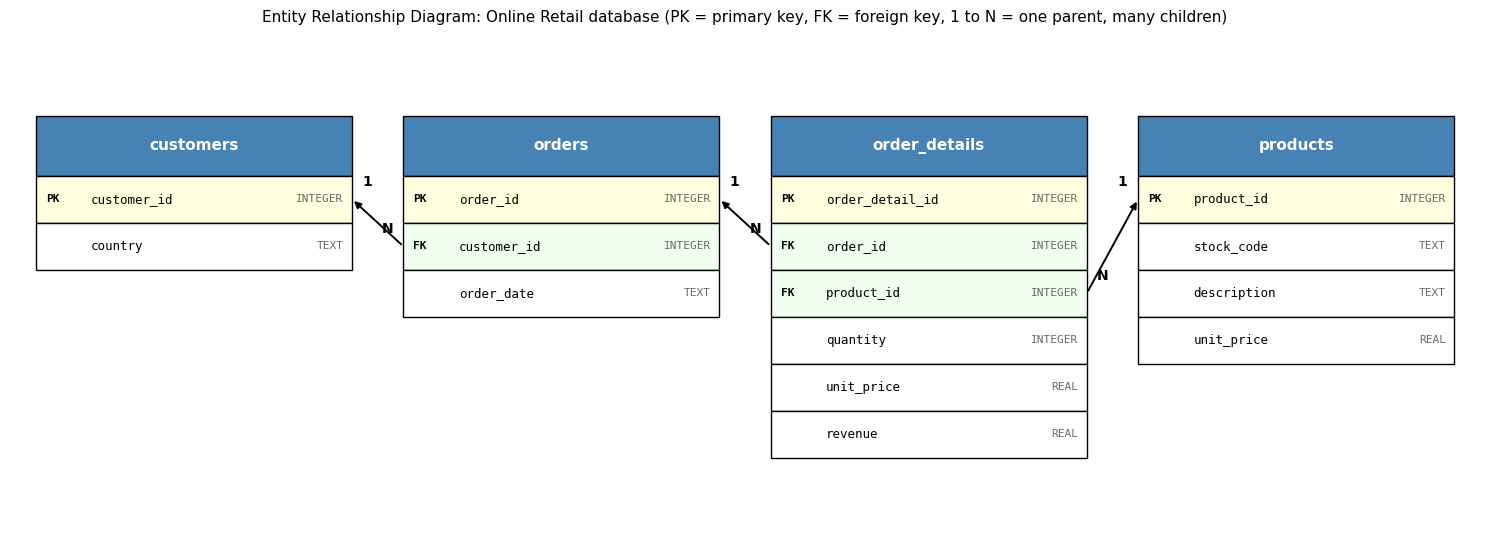

In [ ]:
ROW_HEIGHT = 0.55
HEADER_HEIGHT = 0.7
BOX_WIDTH = 3.7
positions = {"customers": (0.3, 7.2), "orders": (4.6, 7.2), "order_details": (8.9, 7.2), "products": (13.2, 7.2)}


def row_center_y(table_name, column_name):
    top = positions[table_name][1]
    names = [column[0] for column in schema[table_name]["columns"]]
    index = names.index(column_name)
    return top - HEADER_HEIGHT - ROW_HEIGHT * index - ROW_HEIGHT / 2


def draw_table(axis, table_name):
    left, top = positions[table_name]
    columns = schema[table_name]["columns"]
    total_height = HEADER_HEIGHT + ROW_HEIGHT * len(columns)
    axis.add_patch(Rectangle((left, top - HEADER_HEIGHT), BOX_WIDTH, HEADER_HEIGHT, facecolor="steelblue", edgecolor="black"))
    axis.text(left + BOX_WIDTH / 2, top - HEADER_HEIGHT / 2, table_name, ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    for index, (name, sql_type, is_primary, is_foreign) in enumerate(columns):
        row_top = top - HEADER_HEIGHT - ROW_HEIGHT * index
        face = "lightyellow" if is_primary else ("honeydew" if is_foreign else "white")
        axis.add_patch(Rectangle((left, row_top - ROW_HEIGHT), BOX_WIDTH, ROW_HEIGHT, facecolor=face, edgecolor="black"))
        tag = "PK" if is_primary else ("FK" if is_foreign else "")
        axis.text(left + 0.12, row_top - ROW_HEIGHT / 2, tag, va="center", fontsize=8, fontweight="bold", family="monospace")
        axis.text(left + 0.65, row_top - ROW_HEIGHT / 2, name, va="center", fontsize=9, family="monospace")
        axis.text(left + BOX_WIDTH - 0.1, row_top - ROW_HEIGHT / 2, sql_type, va="center", ha="right", fontsize=8, color="dimgray", family="monospace")
    return total_height


figure, axis = plt.subplots(figsize=(15, 5.6))
for table_name in positions:
    draw_table(axis, table_name)

for child, info in schema.items():
    for child_column, parent, parent_column in info["foreign_keys"]:
        child_left = positions[child][0]
        parent_left = positions[parent][0]
        child_is_right = child_left > parent_left
        if child_is_right:
            start_x, end_x = child_left, parent_left + BOX_WIDTH
        else:
            start_x, end_x = child_left + BOX_WIDTH, parent_left
        start_y = row_center_y(child, child_column)
        end_y = row_center_y(parent, parent_column)
        axis.annotate("", xy=(end_x, end_y), xytext=(start_x, start_y), arrowprops=dict(arrowstyle="-|>", color="black", lw=1.4))
        direction = -1 if child_is_right else 1
        axis.text(start_x + 0.18 * direction, start_y + 0.15, "N", fontsize=10, fontweight="bold", ha="center")
        axis.text(end_x - 0.18 * direction, end_y + 0.15, "1", fontsize=10, fontweight="bold", ha="center")

axis.set_xlim(0, 17.2)
axis.set_ylim(2.4, 8.2)
axis.set_aspect("equal")
axis.axis("off")
axis.set_title("Entity Relationship Diagram: Online Retail database (PK = primary key, FK = foreign key, 1 to N = one parent, many children)", fontsize=11)
plt.tight_layout()
plt.show()

## Section 6: Load Data

Load parents first (customers, products), then orders, then order details. Foreign keys are on, so bad rows would fail.

In [ ]:
orders_to_load = orders_df.assign(order_date=orders_df["order_date"].dt.strftime("%Y-%m-%d %H:%M:%S"))
load_plan = [
    ("customers", customers_df),
    ("products", products_df),
    ("orders", orders_to_load),
    ("order_details", order_details_df),
]
orders_to_load.head()

,order_id,customer_id,order_date
0,536365,17850,2010-12-01 08:26:00
1,536366,17850,2010-12-01 08:28:00
2,536367,13047,2010-12-01 08:34:00
3,536368,13047,2010-12-01 08:34:00
4,536369,13047,2010-12-01 08:35:00


In [ ]:
load_results = []
for table_name, frame in load_plan:
    inserted = frame.to_sql(table_name, connection, if_exists="append", index=False, chunksize=50000)
    connection.commit()
    load_results.append({"table": table_name, "rows_in_dataframe": len(frame), "rows_inserted": inserted})
    print(f"Loaded {table_name}: {inserted:,} rows")

load_summary = pd.DataFrame(load_results)
load_summary

Loaded customers: 4,324 rows


Loaded products: 3,646 rows


Loaded orders: 18,325 rows


Loaded order_details: 388,353 rows


,table,rows_in_dataframe,rows_inserted
0,customers,4324,4324
1,products,3646,3646
2,orders,18325,18325
3,order_details,388353,388353


## Section 7: Database Validation

SQL checks on the database, compared with Pandas. PASS/FAIL table at the end.

In [ ]:
validation_results = []


def record_check(area, check, passed, detail):
    validation_results.append({"area": area, "check": check, "result": "PASS" if passed else "FAIL", "detail": detail})


existing_tables = {row[0] for row in connection.execute("SELECT name FROM sqlite_master WHERE type = 'table' AND name NOT LIKE 'sqlite_%'")}
expected_tables = {"customers", "products", "orders", "order_details"}
record_check("Tables", "all four tables exist", existing_tables == expected_tables, ", ".join(sorted(existing_tables)))
pd.read_sql_query("SELECT name AS table_name FROM sqlite_master WHERE type = 'table' AND name NOT LIKE 'sqlite_%' ORDER BY name", connection)

,table_name
0,customers
1,order_details
2,orders
3,products


In [ ]:
pandas_counts = {"customers": len(customers_df), "products": len(products_df), "orders": len(orders_df), "order_details": len(order_details_df)}
count_rows = []
for table_name, expected in pandas_counts.items():
    sql_count = connection.execute(f"SELECT COUNT(*) FROM {table_name}").fetchone()[0]
    count_rows.append({"table": table_name, "sql_rows": sql_count, "pandas_rows": expected, "match": sql_count == expected})
    record_check("Row counts", f"{table_name} rows equal the DataFrame", sql_count == expected, f"{sql_count:,}")
pd.DataFrame(count_rows)

,table,sql_rows,pandas_rows,match
0,customers,4324,4324,True
1,products,3646,3646,True
2,orders,18325,18325,True
3,order_details,388353,388353,True


In [ ]:
primary_key_rows = []
for table_name in expected_tables:
    info = pd.read_sql_query(f"PRAGMA table_info({table_name})", connection)
    key_column = info.loc[info["pk"] == 1, "name"].iloc[0]
    total, distinct = connection.execute(f"SELECT COUNT(*), COUNT(DISTINCT {key_column}) FROM {table_name}").fetchone()
    primary_key_rows.append({"table": table_name, "primary_key": key_column, "rows": total, "distinct_keys": distinct})
    record_check("Primary keys", f"{table_name}.{key_column} is unique and complete", total == distinct, f"{distinct:,} keys")
pd.DataFrame(primary_key_rows).sort_values("table")

,table,primary_key,rows,distinct_keys
0,customers,customer_id,4324,4324
1,order_details,order_detail_id,388353,388353
3,orders,order_id,18325,18325
2,products,product_id,3646,3646


In [ ]:
foreign_key_definitions = pd.concat(
    [pd.read_sql_query(f"PRAGMA foreign_key_list({name})", connection).assign(child_table=name) for name in ["orders", "order_details"]]
)[["child_table", "from", "table", "to"]].rename(columns={"from": "child_column", "table": "parent_table", "to": "parent_column"})
display(foreign_key_definitions)

violations = connection.execute("PRAGMA foreign_key_check").fetchall()
record_check("Foreign keys", "PRAGMA foreign_key_check reports no violations", len(violations) == 0, f"{len(violations)} violations")

orphan_queries = {
    "orders without a customer": "SELECT COUNT(*) FROM orders o LEFT JOIN customers c ON c.customer_id = o.customer_id WHERE c.customer_id IS NULL",
    "order lines without an order": "SELECT COUNT(*) FROM order_details od LEFT JOIN orders o ON o.order_id = od.order_id WHERE o.order_id IS NULL",
    "order lines without a product": "SELECT COUNT(*) FROM order_details od LEFT JOIN products p ON p.product_id = od.product_id WHERE p.product_id IS NULL",
}
orphan_rows = []
for label, query in orphan_queries.items():
    count = connection.execute(query).fetchone()[0]
    orphan_rows.append({"check": label, "orphans": count})
    record_check("Foreign keys", label + " is zero", count == 0, f"{count} orphans")
pd.DataFrame(orphan_rows)

,child_table,child_column,parent_table,parent_column
0,orders,customer_id,customers,customer_id
0,order_details,product_id,products,product_id
1,order_details,order_id,orders,order_id


,check,orphans
0,orders without a customer,0
1,order lines without an order,0
2,order lines without a product,0


In [ ]:
null_rows = []
for table_name in sorted(expected_tables):
    columns = pd.read_sql_query(f"PRAGMA table_info({table_name})", connection)["name"].tolist()
    select_list = ", ".join(f"SUM(CASE WHEN {column} IS NULL THEN 1 ELSE 0 END) AS {column}" for column in columns)
    nulls = pd.read_sql_query(f"SELECT {select_list} FROM {table_name}", connection).iloc[0]
    null_rows.append({"table": table_name, "null_values": int(nulls.sum())})
    record_check("Missing values", f"{table_name} has no NULL values", int(nulls.sum()) == 0, f"{int(nulls.sum())} NULLs")
pd.DataFrame(null_rows)

,table,null_values
0,customers,0
1,order_details,0
2,orders,0
3,products,0


In [ ]:
sql_revenue = connection.execute("SELECT SUM(revenue) FROM order_details").fetchone()[0]
pandas_revenue = order_details_df["revenue"].sum()
formula_errors = connection.execute("SELECT COUNT(*) FROM order_details WHERE ABS(revenue - quantity * unit_price) > 0.005").fetchone()[0]
record_check("Revenue", "SQL revenue total equals Pandas revenue total", abs(sql_revenue - pandas_revenue) < 0.01, f"{sql_revenue:,.2f}")
record_check("Revenue", "revenue equals quantity x unit_price on every row", formula_errors == 0, f"{formula_errors} mismatches")

pd.DataFrame(
    {
        "source": ["SQLite (SUM of order_details.revenue)", "Pandas (sum of order_details_df.revenue)"],
        "total_revenue": [sql_revenue, pandas_revenue],
    }
)

,source,total_revenue
0,SQLite (SUM of order_details.revenue),"8,349,645.02"
1,Pandas (sum of order_details_df.revenue),"8,349,645.02"


In [ ]:
sql_monthly = pd.read_sql_query(
    """
SELECT strftime('%Y-%m', o.order_date) AS year_month, ROUND(SUM(od.revenue), 2) AS sql_revenue
FROM order_details od
JOIN orders o ON o.order_id = od.order_id
GROUP BY strftime('%Y-%m', o.order_date)
ORDER BY year_month
""",
    connection,
)
pandas_monthly = (
    order_details_df.merge(orders_df, on="order_id")
    .assign(year_month=lambda frame: frame["order_date"].dt.strftime("%Y-%m"))
    .groupby("year_month")["revenue"].sum().round(2).rename("pandas_revenue").reset_index()
)
monthly_comparison = sql_monthly.merge(pandas_monthly, on="year_month")
monthly_comparison["difference"] = (monthly_comparison["sql_revenue"] - monthly_comparison["pandas_revenue"]).round(2)
record_check("Relationships", "monthly revenue through joins equals Pandas", bool((monthly_comparison["difference"].abs() < 0.01).all()) and len(monthly_comparison) == len(sql_monthly), f"{len(monthly_comparison)} months")

joined_rows = connection.execute(
    """
SELECT COUNT(*)
FROM order_details od
JOIN orders o ON o.order_id = od.order_id
JOIN customers c ON c.customer_id = o.customer_id
JOIN products p ON p.product_id = od.product_id
"""
).fetchone()[0]
record_check("Relationships", "four-table join returns every order line", joined_rows == len(order_details_df), f"{joined_rows:,} rows")
monthly_comparison

,year_month,sql_revenue,pandas_revenue,difference
0,2010-12,"554,230.92","554,230.92",0.00
1,2011-01,"454,888.11","454,888.11",0.00
2,2011-02,"438,390.02","438,390.02",0.00
3,2011-03,"573,294.62","573,294.62",0.00
4,2011-04,"450,140.05","450,140.05",0.00
5,2011-05,"652,185.47","652,185.47",0.00
6,2011-06,"644,183.90","644,183.90",0.00
7,2011-07,"582,273.78","582,273.78",0.00
8,2011-08,"630,531.59","630,531.59",0.00
9,2011-09,"928,107.71","928,107.71",0.00


In [ ]:
rejected_rows = connection.execute("SELECT COUNT(*) FROM order_details").fetchone()[0]
try:
    connection.execute("INSERT INTO order_details (order_detail_id, order_id, product_id, quantity, unit_price, revenue) VALUES (999999999, -1, -1, 1, 1.0, 1.0)")
    connection.commit()
    foreign_key_enforced = False
    message = "The invalid row was accepted"
except sqlite3.IntegrityError as error:
    connection.rollback()
    foreign_key_enforced = True
    message = str(error)
rows_after_attempt = connection.execute("SELECT COUNT(*) FROM order_details").fetchone()[0]
record_check("Constraints", "a row with an invalid foreign key is rejected", foreign_key_enforced and rows_after_attempt == rejected_rows, message)
print("Database response to an invalid row:", message)
print("Rows before and after the attempt:", rejected_rows, rows_after_attempt)

Database response to an invalid row: FOREIGN KEY constraint failed
Rows before and after the attempt: 388353 388353


In [ ]:
integrity = connection.execute("PRAGMA integrity_check").fetchone()[0]
record_check("Integrity", "SQLite integrity_check returns ok", integrity == "ok", integrity)

validation_df = pd.DataFrame(validation_results)
failed = validation_df[validation_df["result"] == "FAIL"]
assert failed.empty, failed
print("Checks passed:", int((validation_df["result"] == "PASS").sum()), "of", len(validation_df))
validation_df

Checks passed: 23 of 23


,area,check,result,detail
0,Tables,all four tables exist,PASS,"customers, order_details, orders, products"
1,Row counts,customers rows equal the DataFrame,PASS,"4,324"
2,Row counts,products rows equal the DataFrame,PASS,"3,646"
3,Row counts,orders rows equal the DataFrame,PASS,"18,325"
4,Row counts,order_details rows equal the DataFrame,PASS,"388,353"
5,Primary keys,customers.customer_id is unique and complete,PASS,"4,324 keys"
6,Primary keys,order_details.order_detail_id is unique and complete,PASS,"388,353 keys"
7,Primary keys,products.product_id is unique and complete,PASS,"3,646 keys"
8,Primary keys,orders.order_id is unique and complete,PASS,"18,325 keys"
9,Foreign keys,PRAGMA foreign_key_check reports no violations,PASS,0 violations


## Section 8: ETL Demonstration

```text
EXTRACT
   ↓
TRANSFORM
   ↓
LOAD
```

Table follows the data through extract, transform and load.

In [ ]:
etl_summary = pd.DataFrame(
    [
        ("EXTRACT", "Extraction", "Read the Excel file from the ZIP archive into raw_df", len(raw_df)),
        ("TRANSFORM", "Cleaning", "Cleaned sales lines after removing duplicates, cancellations, invalid values and missing customers", len(clean_df)),
        ("TRANSFORM", "Cleaning", "Orders built from the clean sales lines", len(orders_df)),
        ("LOAD", "Database", "order_details rows stored in SQLite", connection.execute("SELECT COUNT(*) FROM order_details").fetchone()[0]),
        ("LOAD", "Database", "orders rows stored in SQLite", connection.execute("SELECT COUNT(*) FROM orders").fetchone()[0]),
        ("LOAD", "Database", "customers rows stored in SQLite", connection.execute("SELECT COUNT(*) FROM customers").fetchone()[0]),
        ("LOAD", "Database", "products rows stored in SQLite", connection.execute("SELECT COUNT(*) FROM products").fetchone()[0]),
    ],
    columns=["stage", "step", "what_happened", "rows"],
)
etl_summary

,stage,step,what_happened,rows
0,EXTRACT,Extraction,Read the Excel file from the ZIP archive into raw_df,541909
1,TRANSFORM,Cleaning,"Cleaned sales lines after removing duplicates, cancellations, invalid values and missing customers",388353
2,TRANSFORM,Cleaning,Orders built from the clean sales lines,18325
3,LOAD,Database,order_details rows stored in SQLite,388353
4,LOAD,Database,orders rows stored in SQLite,18325
5,LOAD,Database,customers rows stored in SQLite,4324
6,LOAD,Database,products rows stored in SQLite,3646


In [ ]:
display(Markdown(
    f"**Extract.** {len(raw_df):,} raw rows were read from the original Excel file, which was never modified. "
    f"**Transform.** The data was cleaned to {len(clean_df):,} valid sales lines, enriched with revenue and date fields, and split into four related tables. "
    f"**Load.** The tables were created with SQL, loaded with Python and validated: {int((validation_df['result'] == 'PASS').sum())} of {len(validation_df)} checks passed and "
    f"the database revenue total of {sql_revenue:,.2f} matches the Pandas total."
))

**Extract.** 541,909 raw rows were read from the original Excel file, which was never modified. **Transform.** The data was cleaned to 388,353 valid sales lines, enriched with revenue and date fields, and split into four related tables. **Load.** The tables were created with SQL, loaded with Python and validated: 23 of 23 checks passed and the database revenue total of 8,349,645.02 matches the Pandas total.

In [ ]:
connection.close()
print("Database closed:", DB_PATH.name, f"({DB_PATH.stat().st_size / 1024 ** 2:.1f} MB)")

Database closed: online_retail.db (23.9 MB)


# SQL Reporting and Final Report

Query the database with SQL, make charts, write the final report and check the requirements.

## Section 1: Database Connection

In [ ]:
import io
import json
import re
import tokenize

pd.set_option("display.max_colwidth", 120)

In [ ]:
DB_PATH = PROJECT_DIR / "online_retail.db"
if not DB_PATH.exists():
    raise FileNotFoundError("online_retail.db was not found. Run the database creation cells first.")

connection = sqlite3.connect(DB_PATH)
connection.execute("PRAGMA foreign_keys = ON")
print("Connected to:", DB_PATH.name, f"({DB_PATH.stat().st_size / 1024 ** 2:.1f} MB)")

Connected to: online_retail.db (23.9 MB)


In [ ]:
table_names = [row[0] for row in connection.execute("SELECT name FROM sqlite_master WHERE type = 'table' AND name NOT LIKE 'sqlite_%' ORDER BY name")]
expected_tables = ["customers", "order_details", "orders", "products"]
print("Expected tables present:", table_names == expected_tables)

table_overview = pd.DataFrame(
    [{"table": name, "rows": connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]} for name in table_names]
)
table_overview

Expected tables present: True


,table,rows
0,customers,4324
1,order_details,388353
2,orders,18325
3,products,3646


In [ ]:
for name in table_names:
    print(name)
    display(pd.read_sql_query(f"SELECT * FROM {name} LIMIT 5", connection))

customers


,customer_id,country
0,12347,Iceland
1,12348,Finland
2,12349,Italy
3,12350,Norway
4,12352,Norway


order_details


,order_detail_id,order_id,product_id,quantity,unit_price,revenue
0,1,536365,750,6,4.25,25.50
1,2,536365,1600,2,7.65,15.30
2,3,536365,2641,6,3.39,20.34
3,4,536365,2792,6,3.39,20.34
4,5,536365,2793,6,3.39,20.34


orders


,order_id,customer_id,order_date
0,536365,17850,2010-12-01 08:26:00
1,536366,17850,2010-12-01 08:28:00
2,536367,13047,2010-12-01 08:34:00
3,536368,13047,2010-12-01 08:34:00
4,536369,13047,2010-12-01 08:35:00


products


,product_id,stock_code,description,unit_price
0,1,10002,INFLATABLE POLITICAL GLOBE,0.85
1,2,10080,GROOVY CACTUS INFLATABLE,0.39
2,3,10120,DOGGY RUBBER,0.21
3,4,10123C,HEARTS WRAPPING TAPE,0.65
4,5,10124A,SPOTS ON RED BOOKCOVER TAPE,0.42


## Section 2: SQL Reports and Results

Each report: show the query, run it, show the result, explain it. Queries are saved so the SQL concepts can be checked later.

In [ ]:
executed_reports = {}
figures_created = []


def run_report(number, title, sql):
    sql = sql.strip()
    display(Markdown(f"#### Report {number}: {title}\n\n```sql\n{sql}\n```"))
    result = pd.read_sql_query(sql, connection)
    executed_reports[f"Report {number}: {title}"] = sql
    return result


def show_figure(figure):
    figures_created.append(figure.layout.title.text)
    figure.show()


total_revenue = connection.execute("SELECT SUM(revenue) FROM order_details").fetchone()[0]
first_order, last_order = connection.execute("SELECT MIN(order_date), MAX(order_date) FROM orders").fetchone()
print("Total revenue in the database:", f"{total_revenue:,.2f}")
print("Order dates range from", first_order, "to", last_order)

Total revenue in the database: 8,349,645.02
Order dates range from 2010-12-01 08:26:00 to 2011-12-09 12:50:00


### Report 1: Total revenue by product

In [ ]:
report_1 = run_report(1, "Total revenue by product", """
SELECT p.stock_code,
       p.description,
       SUM(od.quantity) AS units_sold,
       ROUND(SUM(od.revenue), 2) AS total_revenue
FROM order_details od
JOIN products p ON p.product_id = od.product_id
GROUP BY p.product_id, p.stock_code, p.description
ORDER BY total_revenue DESC
LIMIT 15
""")
report_1

#### Report 1: Total revenue by product

```sql
SELECT p.stock_code,
       p.description,
       SUM(od.quantity) AS units_sold,
       ROUND(SUM(od.revenue), 2) AS total_revenue
FROM order_details od
JOIN products p ON p.product_id = od.product_id
GROUP BY p.product_id, p.stock_code, p.description
ORDER BY total_revenue DESC
LIMIT 15
```

,stock_code,description,units_sold,total_revenue
0,22423,REGENCY CAKESTAND 3 TIER,12031,"138,363.10"
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,34239,"94,073.65"
2,85099B,JUMBO BAG RED RETROSPOT,45197,"83,526.56"
3,47566,PARTY BUNTING,15086,"67,950.48"
4,84879,ASSORTED COLOUR BIRD ORNAMENT,35234,"56,364.02"
5,23084,RABBIT NIGHT LIGHT,27123,"51,188.84"
6,22502,PICNIC BASKET WICKER SMALL,1417,"47,003.75"
7,79321,CHILLI LIGHTS,9569,"45,930.36"
8,22086,PAPER CHAIN KIT 50'S CHRISTMAS,15184,"41,543.48"
9,21137,BLACK RECORD COVER FRAME,11389,"39,000.80"


In [ ]:
top_product = report_1.iloc[0]
display(Markdown(
    f"**Interpretation.** {top_product['description']} is the highest earning product with {top_product['total_revenue']:,.2f} from {int(top_product['units_sold']):,} units. "
    f"The fifteen products shown together bring in {report_1['total_revenue'].sum():,.2f}, which is {report_1['total_revenue'].sum() / total_revenue * 100:.1f}% of all revenue."
))

**Interpretation.** REGENCY CAKESTAND 3 TIER is the highest earning product with 138,363.10 from 12,031 units. The fifteen products shown together bring in 845,955.02, which is 10.1% of all revenue.

### Report 2: Monthly revenue

In [ ]:
report_2 = run_report(2, "Monthly revenue", """
SELECT strftime('%Y-%m', o.order_date) AS year_month,
       ROUND(SUM(od.revenue), 2) AS revenue,
       COUNT(DISTINCT o.order_id) AS orders,
       COUNT(DISTINCT o.customer_id) AS active_customers
FROM orders o
JOIN order_details od ON od.order_id = o.order_id
GROUP BY strftime('%Y-%m', o.order_date)
ORDER BY year_month
""")
report_2

#### Report 2: Monthly revenue

```sql
SELECT strftime('%Y-%m', o.order_date) AS year_month,
       ROUND(SUM(od.revenue), 2) AS revenue,
       COUNT(DISTINCT o.order_id) AS orders,
       COUNT(DISTINCT o.customer_id) AS active_customers
FROM orders o
JOIN order_details od ON od.order_id = o.order_id
GROUP BY strftime('%Y-%m', o.order_date)
ORDER BY year_month
```

,year_month,revenue,orders,active_customers
0,2010-12,"554,230.92",1387,883
1,2011-01,"454,888.11",977,738
2,2011-02,"438,390.02",989,756
3,2011-03,"573,294.62",1306,970
4,2011-04,"450,140.05",1133,850
5,2011-05,"652,185.47",1537,1051
6,2011-06,"644,183.90",1382,989
7,2011-07,"582,273.78",1316,946
8,2011-08,"630,531.59",1264,933
9,2011-09,"928,107.71",1733,1256


In [ ]:
last_order_ts = pd.Timestamp(last_order)
last_month_label = last_order_ts.strftime("%Y-%m")
last_month_partial = last_order_ts.normalize() < (last_order_ts + pd.offsets.MonthEnd(0)).normalize()
report_2["status"] = np.where((report_2["year_month"] == last_month_label) & last_month_partial, "Incomplete month", "Complete month")
complete_months_sql = report_2[report_2["status"] == "Complete month"]
peak_month = complete_months_sql.loc[complete_months_sql["revenue"].idxmax()]
low_month = complete_months_sql.loc[complete_months_sql["revenue"].idxmin()]
display(Markdown(
    f"**Interpretation.** Revenue is highest in {peak_month['year_month']} ({peak_month['revenue']:,.2f}) and lowest among complete months in {low_month['year_month']} ({low_month['revenue']:,.2f}). "
    f"{last_month_label} is incomplete because the last order is dated {last_order}."
))

**Interpretation.** Revenue is highest in 2011-11 (1,126,034.40) and lowest among complete months in 2011-02 (438,390.02). 2011-12 is incomplete because the last order is dated 2011-12-09 12:50:00.

### Report 3: Top 10 customers by revenue

In [ ]:
report_3 = run_report(3, "Top 10 customers by revenue", """
SELECT c.customer_id,
       c.country,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(od.revenue), 2) AS total_revenue,
       MIN(o.order_date) AS first_order,
       MAX(o.order_date) AS last_order
FROM customers c
JOIN orders o ON o.customer_id = c.customer_id
JOIN order_details od ON od.order_id = o.order_id
GROUP BY c.customer_id, c.country
ORDER BY total_revenue DESC
LIMIT 10
""")
report_3

#### Report 3: Top 10 customers by revenue

```sql
SELECT c.customer_id,
       c.country,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(od.revenue), 2) AS total_revenue,
       MIN(o.order_date) AS first_order,
       MAX(o.order_date) AS last_order
FROM customers c
JOIN orders o ON o.customer_id = c.customer_id
JOIN order_details od ON od.order_id = o.order_id
GROUP BY c.customer_id, c.country
ORDER BY total_revenue DESC
LIMIT 10
```

,customer_id,country,orders,total_revenue,first_order,last_order
0,14646,Netherlands,72,"278,778.02",2010-12-20 10:09:00,2011-12-08 12:12:00
1,18102,United Kingdom,60,"259,657.30",2010-12-07 16:42:00,2011-12-09 11:50:00
2,17450,United Kingdom,45,"189,607.53",2010-12-07 09:23:00,2011-12-01 13:29:00
3,14911,EIRE,196,"129,654.58",2010-12-01 14:05:00,2011-12-08 15:54:00
4,12415,Australia,19,"123,806.88",2011-01-06 11:12:00,2011-11-15 14:22:00
5,14156,EIRE,54,"113,866.28",2010-12-03 11:48:00,2011-11-30 10:54:00
6,17511,United Kingdom,31,"88,640.38",2010-12-01 10:19:00,2011-12-07 10:12:00
7,16684,United Kingdom,28,"65,920.12",2010-12-16 17:34:00,2011-12-05 14:06:00
8,13694,United Kingdom,50,"63,601.38",2010-12-01 12:12:00,2011-12-06 09:32:00
9,16029,United Kingdom,60,"60,396.93",2010-12-01 09:57:00,2011-11-01 10:27:00


In [ ]:
top10_customer_revenue = report_3["total_revenue"].sum()
display(Markdown(
    f"**Interpretation.** Customer {int(report_3.iloc[0]['customer_id'])} from {report_3.iloc[0]['country']} is the largest customer with {report_3.iloc[0]['total_revenue']:,.2f}. "
    f"The top 10 customers contribute {top10_customer_revenue:,.2f}, or {top10_customer_revenue / total_revenue * 100:.1f}% of all revenue."
))

**Interpretation.** Customer 14646 from Netherlands is the largest customer with 278,778.02. The top 10 customers contribute 1,373,929.40, or 16.5% of all revenue.

### Report 4: Top-performing products

In [ ]:
report_4 = run_report(4, "Top-performing products (sold in at least 100 orders)", """
SELECT p.stock_code,
       p.description,
       COUNT(DISTINCT od.order_id) AS orders,
       SUM(od.quantity) AS units_sold,
       ROUND(AVG(od.unit_price), 2) AS average_price,
       MIN(od.unit_price) AS lowest_price,
       MAX(od.unit_price) AS highest_price,
       ROUND(SUM(od.revenue), 2) AS total_revenue
FROM order_details od
JOIN products p ON p.product_id = od.product_id
WHERE od.quantity > 0
GROUP BY p.product_id, p.stock_code, p.description
HAVING COUNT(DISTINCT od.order_id) >= 100
ORDER BY total_revenue DESC
LIMIT 10
""")
report_4

#### Report 4: Top-performing products (sold in at least 100 orders)

```sql
SELECT p.stock_code,
       p.description,
       COUNT(DISTINCT od.order_id) AS orders,
       SUM(od.quantity) AS units_sold,
       ROUND(AVG(od.unit_price), 2) AS average_price,
       MIN(od.unit_price) AS lowest_price,
       MAX(od.unit_price) AS highest_price,
       ROUND(SUM(od.revenue), 2) AS total_revenue
FROM order_details od
JOIN products p ON p.product_id = od.product_id
WHERE od.quantity > 0
GROUP BY p.product_id, p.stock_code, p.description
HAVING COUNT(DISTINCT od.order_id) >= 100
ORDER BY total_revenue DESC
LIMIT 10
```

,stock_code,description,orders,units_sold,average_price,lowest_price,highest_price,total_revenue
0,22423,REGENCY CAKESTAND 3 TIER,1662,12031,12.48,4.00,24.96,"138,363.10"
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1966,34239,2.89,2.40,5.79,"94,073.65"
2,85099B,JUMBO BAG RED RETROSPOT,1589,45197,2.02,1.65,4.13,"83,526.56"
3,47566,PARTY BUNTING,1368,15086,4.88,3.75,10.79,"67,950.48"
4,84879,ASSORTED COLOUR BIRD ORNAMENT,1372,35234,1.68,1.45,1.69,"56,364.02"
5,23084,RABBIT NIGHT LIGHT,798,27123,2.01,1.67,4.13,"51,188.84"
6,22502,PICNIC BASKET WICKER SMALL,231,1417,11.34,2.00,649.50,"47,003.75"
7,79321,CHILLI LIGHTS,516,9569,5.43,3.82,12.46,"45,930.36"
8,22086,PAPER CHAIN KIT 50'S CHRISTMAS,972,15184,2.94,2.55,5.79,"41,543.48"
9,21137,BLACK RECORD COVER FRAME,310,11389,3.66,3.39,7.46,"39,000.80"


In [ ]:
frequent = report_4.sort_values("orders", ascending=False).iloc[0]
display(Markdown(
    f"**Interpretation.** Only products that appear in at least 100 different orders are considered, which separates steady sellers from one-off bulk sales. "
    f"{report_4.iloc[0]['description']} leads on revenue, and {frequent['description']} appears in the most orders ({int(frequent['orders']):,}). "
    f"The price range of the leading product runs from {report_4.iloc[0]['lowest_price']:,.2f} to {report_4.iloc[0]['highest_price']:,.2f}."
))

**Interpretation.** Only products that appear in at least 100 different orders are considered, which separates steady sellers from one-off bulk sales. REGENCY CAKESTAND 3 TIER leads on revenue, and WHITE HANGING HEART T-LIGHT HOLDER appears in the most orders (1,966). The price range of the leading product runs from 4.00 to 24.96.

### Report 5: Revenue by country

In [ ]:
report_5 = run_report(5, "Revenue by country", """
SELECT c.country,
       COUNT(DISTINCT c.customer_id) AS customers,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(od.revenue), 2) AS total_revenue,
       ROUND(100.0 * SUM(od.revenue) / (SELECT SUM(revenue) FROM order_details), 2) AS revenue_share_percent
FROM customers c
JOIN orders o ON o.customer_id = c.customer_id
JOIN order_details od ON od.order_id = o.order_id
GROUP BY c.country
ORDER BY total_revenue DESC
LIMIT 15
""")
report_5

#### Report 5: Revenue by country

```sql
SELECT c.country,
       COUNT(DISTINCT c.customer_id) AS customers,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(od.revenue), 2) AS total_revenue,
       ROUND(100.0 * SUM(od.revenue) / (SELECT SUM(revenue) FROM order_details), 2) AS revenue_share_percent
FROM customers c
JOIN orders o ON o.customer_id = c.customer_id
JOIN order_details od ON od.order_id = o.order_id
GROUP BY c.country
ORDER BY total_revenue DESC
LIMIT 15
```

,country,customers,orders,total_revenue,revenue_share_percent
0,United Kingdom,3909,16512,"6,876,546.64",82.36
1,Netherlands,9,93,"283,479.54",3.40
2,EIRE,3,254,"247,812.07",2.97
3,Germany,94,443,"203,849.48",2.44
4,France,87,379,"182,143.53",2.18
5,Australia,9,56,"138,289.19",1.66
6,Spain,28,87,"53,361.57",0.64
7,Switzerland,20,46,"51,992.79",0.62
8,Japan,8,19,"37,314.37",0.45
9,Belgium,24,98,"37,027.61",0.44


In [ ]:
home_market = report_5.iloc[0]["country"]
display(Markdown(
    f"**Interpretation.** {home_market} accounts for {report_5.iloc[0]['revenue_share_percent']:.1f}% of revenue. "
    f"The next market, {report_5.iloc[1]['country']}, has {report_5.iloc[1]['revenue_share_percent']:.1f}%. "
    f"The percentage is calculated with a subquery that returns the total revenue of the whole database."
))

**Interpretation.** United Kingdom accounts for 82.4% of revenue. The next market, Netherlands, has 3.4%. The percentage is calculated with a subquery that returns the total revenue of the whole database.

### Report 6: Average order value

In [ ]:
report_6 = run_report(6, "Average order value", """
SELECT COUNT(*) AS orders,
       ROUND(AVG(order_total), 2) AS average_order_value,
       ROUND(MIN(order_total), 2) AS smallest_order,
       ROUND(MAX(order_total), 2) AS largest_order,
       ROUND(SUM(order_total), 2) AS total_revenue
FROM (
    SELECT order_id, SUM(revenue) AS order_total
    FROM order_details
    GROUP BY order_id
) AS order_totals
""")
report_6

#### Report 6: Average order value

```sql
SELECT COUNT(*) AS orders,
       ROUND(AVG(order_total), 2) AS average_order_value,
       ROUND(MIN(order_total), 2) AS smallest_order,
       ROUND(MAX(order_total), 2) AS largest_order,
       ROUND(SUM(order_total), 2) AS total_revenue
FROM (
    SELECT order_id, SUM(revenue) AS order_total
    FROM order_details
    GROUP BY order_id
) AS order_totals
```

,orders,average_order_value,smallest_order,largest_order,total_revenue
0,18325,455.64,0.38,"38,970.00","8,349,645.02"


In [ ]:
average_order_value = report_6.iloc[0]["average_order_value"]
display(Markdown(
    f"**Interpretation.** The {int(report_6.iloc[0]['orders']):,} orders have an average value of {average_order_value:,.2f}. "
    f"Order sizes range from {report_6.iloc[0]['smallest_order']:,.2f} to {report_6.iloc[0]['largest_order']:,.2f}. "
    f"The total of {report_6.iloc[0]['total_revenue']:,.2f} equals the revenue total of the database."
))

**Interpretation.** The 18,325 orders have an average value of 455.64. Order sizes range from 0.38 to 38,970.00. The total of 8,349,645.02 equals the revenue total of the database.

### Report 7: Number of orders by month

In [ ]:
report_7 = run_report(7, "Number of orders by month", """
SELECT strftime('%Y-%m', o.order_date) AS year_month,
       COUNT(DISTINCT o.order_id) AS orders,
       SUM(od.quantity) AS units_sold,
       ROUND(1.0 * SUM(od.quantity) / COUNT(DISTINCT o.order_id), 1) AS units_per_order,
       ROUND(SUM(od.revenue) / COUNT(DISTINCT o.order_id), 2) AS average_order_value
FROM orders o
JOIN order_details od ON od.order_id = o.order_id
GROUP BY strftime('%Y-%m', o.order_date)
ORDER BY year_month
""")
report_7

#### Report 7: Number of orders by month

```sql
SELECT strftime('%Y-%m', o.order_date) AS year_month,
       COUNT(DISTINCT o.order_id) AS orders,
       SUM(od.quantity) AS units_sold,
       ROUND(1.0 * SUM(od.quantity) / COUNT(DISTINCT o.order_id), 1) AS units_per_order,
       ROUND(SUM(od.revenue) / COUNT(DISTINCT o.order_id), 2) AS average_order_value
FROM orders o
JOIN order_details od ON od.order_id = o.order_id
GROUP BY strftime('%Y-%m', o.order_date)
ORDER BY year_month
```

,year_month,orders,units_sold,units_per_order,average_order_value
0,2010-12,1387,305978,220.60,399.59
1,2011-01,977,261356,267.50,465.60
2,2011-02,989,263381,266.30,443.27
3,2011-03,1306,343541,263.00,438.97
4,2011-04,1133,289032,255.10,397.30
5,2011-05,1537,368830,240.00,424.32
6,2011-06,1382,356321,257.80,466.12
7,2011-07,1316,362040,275.10,442.46
8,2011-08,1264,394839,312.40,498.84
9,2011-09,1733,539047,311.00,535.55


In [ ]:
busiest = report_7.loc[report_7["orders"].idxmax()]
display(Markdown(
    f"**Interpretation.** {busiest['year_month']} is the month with the most orders ({int(busiest['orders']):,}). "
    f"Monthly average order value ranges from {report_7['average_order_value'].min():,.2f} to {report_7['average_order_value'].max():,.2f}, so order volume and order size do not always move together."
))

**Interpretation.** 2011-11 is the month with the most orders (2,637). Monthly average order value ranges from 397.30 to 535.55, so order volume and order size do not always move together.

### Report 8: Products with revenue above the average product revenue

In [ ]:
report_8 = run_report(8, "Products with revenue above the average product revenue", """
SELECT p.stock_code,
       p.description,
       ROUND(SUM(od.revenue), 2) AS total_revenue
FROM order_details od
JOIN products p ON p.product_id = od.product_id
GROUP BY p.product_id, p.stock_code, p.description
HAVING SUM(od.revenue) > (
    SELECT AVG(product_revenue)
    FROM (
        SELECT SUM(revenue) AS product_revenue
        FROM order_details
        GROUP BY product_id
    ) AS revenue_per_product
)
ORDER BY total_revenue DESC
""")
products_sold = connection.execute("SELECT COUNT(DISTINCT product_id) FROM order_details").fetchone()[0]
average_product_revenue = total_revenue / products_sold
print("Products above the average:", len(report_8), "of", products_sold, "| average product revenue:", f"{average_product_revenue:,.2f}")
report_8.head(15)

#### Report 8: Products with revenue above the average product revenue

```sql
SELECT p.stock_code,
       p.description,
       ROUND(SUM(od.revenue), 2) AS total_revenue
FROM order_details od
JOIN products p ON p.product_id = od.product_id
GROUP BY p.product_id, p.stock_code, p.description
HAVING SUM(od.revenue) > (
    SELECT AVG(product_revenue)
    FROM (
        SELECT SUM(revenue) AS product_revenue
        FROM order_details
        GROUP BY product_id
    ) AS revenue_per_product
)
ORDER BY total_revenue DESC
```

Products above the average: 831 of 3646 | average product revenue: 2,290.08


,stock_code,description,total_revenue
0,22423,REGENCY CAKESTAND 3 TIER,"138,363.10"
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"94,073.65"
2,85099B,JUMBO BAG RED RETROSPOT,"83,526.56"
3,47566,PARTY BUNTING,"67,950.48"
4,84879,ASSORTED COLOUR BIRD ORNAMENT,"56,364.02"
5,23084,RABBIT NIGHT LIGHT,"51,188.84"
6,22502,PICNIC BASKET WICKER SMALL,"47,003.75"
7,79321,CHILLI LIGHTS,"45,930.36"
8,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"41,543.48"
9,21137,BLACK RECORD COVER FRAME,"39,000.80"


In [ ]:
above_average_share = report_8["total_revenue"].sum() / total_revenue * 100
display(Markdown(
    f"**Interpretation.** The average product earns {average_product_revenue:,.2f}. {len(report_8):,} products ({len(report_8) / products_sold * 100:.1f}% of the products sold) earn more than this, "
    f"and together they generate {above_average_share:.1f}% of all revenue."
))

**Interpretation.** The average product earns 2,290.08. 831 products (22.8% of the products sold) earn more than this, and together they generate 80.9% of all revenue.

### Report 9: Average order value by market

In [ ]:
report_9 = run_report(9, "Average order value, home market compared with other countries", f"""
SELECT CASE WHEN c.country = '{home_market}' THEN '{home_market}' ELSE 'Other countries' END AS market,
       COUNT(*) AS orders,
       ROUND(AVG(t.order_total), 2) AS average_order_value,
       ROUND(MIN(t.order_total), 2) AS smallest_order,
       ROUND(MAX(t.order_total), 2) AS largest_order
FROM (
    SELECT order_id, SUM(revenue) AS order_total
    FROM order_details
    GROUP BY order_id
) AS t
JOIN orders o ON o.order_id = t.order_id
JOIN customers c ON c.customer_id = o.customer_id
GROUP BY market
ORDER BY average_order_value DESC
""")
report_9

#### Report 9: Average order value, home market compared with other countries

```sql
SELECT CASE WHEN c.country = 'United Kingdom' THEN 'United Kingdom' ELSE 'Other countries' END AS market,
       COUNT(*) AS orders,
       ROUND(AVG(t.order_total), 2) AS average_order_value,
       ROUND(MIN(t.order_total), 2) AS smallest_order,
       ROUND(MAX(t.order_total), 2) AS largest_order
FROM (
    SELECT order_id, SUM(revenue) AS order_total
    FROM order_details
    GROUP BY order_id
) AS t
JOIN orders o ON o.order_id = t.order_id
JOIN customers c ON c.customer_id = o.customer_id
GROUP BY market
ORDER BY average_order_value DESC
```

,market,orders,average_order_value,smallest_order,largest_order
0,Other countries,1813,812.52,1.45,"22,775.93"
1,United Kingdom,16512,416.46,0.38,"38,970.00"


In [ ]:
display(Markdown(
    f"**Interpretation.** The market with the higher average order value is {report_9.iloc[0]['market']} ({report_9.iloc[0]['average_order_value']:,.2f}), "
    f"against {report_9.iloc[1]['average_order_value']:,.2f} for {report_9.iloc[1]['market']}."
))

**Interpretation.** The market with the higher average order value is Other countries (812.52), against 416.46 for United Kingdom.

### Report 10: Orders grouped by value band

In [ ]:
report_10 = run_report(10, "Orders grouped by value band", """
SELECT CASE
           WHEN t.order_total < 200 THEN 'Under 200'
           WHEN t.order_total < 500 THEN '200 to 499.99'
           WHEN t.order_total < 1500 THEN '500 to 1499.99'
           ELSE '1500 and above'
       END AS order_value_band,
       COUNT(*) AS orders,
       ROUND(SUM(t.order_total), 2) AS revenue,
       ROUND(100.0 * SUM(t.order_total) / (SELECT SUM(revenue) FROM order_details), 2) AS revenue_share_percent
FROM (
    SELECT order_id, SUM(revenue) AS order_total
    FROM order_details
    GROUP BY order_id
) AS t
GROUP BY order_value_band
ORDER BY MIN(t.order_total)
""")
report_10

#### Report 10: Orders grouped by value band

```sql
SELECT CASE
           WHEN t.order_total < 200 THEN 'Under 200'
           WHEN t.order_total < 500 THEN '200 to 499.99'
           WHEN t.order_total < 1500 THEN '500 to 1499.99'
           ELSE '1500 and above'
       END AS order_value_band,
       COUNT(*) AS orders,
       ROUND(SUM(t.order_total), 2) AS revenue,
       ROUND(100.0 * SUM(t.order_total) / (SELECT SUM(revenue) FROM order_details), 2) AS revenue_share_percent
FROM (
    SELECT order_id, SUM(revenue) AS order_total
    FROM order_details
    GROUP BY order_id
) AS t
GROUP BY order_value_band
ORDER BY MIN(t.order_total)
```

,order_value_band,orders,revenue,revenue_share_percent
0,Under 200,6204,"700,155.10",8.39
1,200 to 499.99,8082,"2,642,318.80",31.65
2,500 to 1499.99,3393,"2,616,460.89",31.34
3,1500 and above,646,"2,390,710.23",28.63


In [ ]:
top_band = report_10.iloc[-1]
display(Markdown(
    f"**Interpretation.** Orders of {top_band['order_value_band']} are only {int(top_band['orders']):,} of {int(report_10['orders'].sum()):,} orders "
    f"({top_band['orders'] / report_10['orders'].sum() * 100:.1f}%) but bring {top_band['revenue_share_percent']:.1f}% of revenue."
))

**Interpretation.** Orders of 1500 and above are only 646 of 18,325 orders (3.5%) but bring 28.6% of revenue.

### Report 11: Revenue by weekday

In [ ]:
report_11 = run_report(11, "Revenue by weekday", """
SELECT CASE strftime('%w', o.order_date)
           WHEN '0' THEN 'Sunday'
           WHEN '1' THEN 'Monday'
           WHEN '2' THEN 'Tuesday'
           WHEN '3' THEN 'Wednesday'
           WHEN '4' THEN 'Thursday'
           WHEN '5' THEN 'Friday'
           WHEN '6' THEN 'Saturday'
       END AS weekday,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(od.revenue), 2) AS revenue
FROM orders o
JOIN order_details od ON od.order_id = o.order_id
GROUP BY strftime('%w', o.order_date)
ORDER BY (CAST(strftime('%w', o.order_date) AS INTEGER) + 6) % 7
""")
report_11

#### Report 11: Revenue by weekday

```sql
SELECT CASE strftime('%w', o.order_date)
           WHEN '0' THEN 'Sunday'
           WHEN '1' THEN 'Monday'
           WHEN '2' THEN 'Tuesday'
           WHEN '3' THEN 'Wednesday'
           WHEN '4' THEN 'Thursday'
           WHEN '5' THEN 'Friday'
           WHEN '6' THEN 'Saturday'
       END AS weekday,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(od.revenue), 2) AS revenue
FROM orders o
JOIN order_details od ON od.order_id = o.order_id
GROUP BY strftime('%w', o.order_date)
ORDER BY (CAST(strftime('%w', o.order_date) AS INTEGER) + 6) % 7
```

,weekday,orders,revenue
0,Monday,2815,"1,307,740.59"
1,Tuesday,3142,"1,560,060.54"
2,Wednesday,3425,"1,540,383.96"
3,Thursday,3986,"1,907,799.72"
4,Friday,2795,"1,262,550.18"
5,Sunday,2162,"771,110.03"


In [ ]:
all_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
missing_days = [day for day in all_days if day not in report_11["weekday"].tolist()]
strongest_day = report_11.loc[report_11["revenue"].idxmax()]
display(Markdown(
    f"**Interpretation.** {strongest_day['weekday']} has the highest revenue ({strongest_day['revenue']:,.2f}). "
    f"Days without any recorded orders: {', '.join(missing_days) if missing_days else 'none'}."
))

**Interpretation.** Thursday has the highest revenue (1,907,799.72). Days without any recorded orders: Saturday.

### Report 12: Customer segments by number of orders

In [ ]:
report_12 = run_report(12, "Customer segments by number of orders", """
SELECT CASE
           WHEN t.order_count = 1 THEN 'One order'
           WHEN t.order_count BETWEEN 2 AND 4 THEN '2 to 4 orders'
           ELSE '5 or more orders'
       END AS customer_segment,
       COUNT(*) AS customers,
       ROUND(SUM(t.revenue), 2) AS revenue,
       ROUND(AVG(t.revenue), 2) AS revenue_per_customer,
       ROUND(100.0 * SUM(t.revenue) / (SELECT SUM(revenue) FROM order_details), 2) AS revenue_share_percent
FROM (
    SELECT o.customer_id,
           COUNT(DISTINCT o.order_id) AS order_count,
           SUM(od.revenue) AS revenue
    FROM orders o
    JOIN order_details od ON od.order_id = o.order_id
    GROUP BY o.customer_id
) AS t
GROUP BY customer_segment
ORDER BY MIN(t.order_count)
""")
report_12

#### Report 12: Customer segments by number of orders

```sql
SELECT CASE
           WHEN t.order_count = 1 THEN 'One order'
           WHEN t.order_count BETWEEN 2 AND 4 THEN '2 to 4 orders'
           ELSE '5 or more orders'
       END AS customer_segment,
       COUNT(*) AS customers,
       ROUND(SUM(t.revenue), 2) AS revenue,
       ROUND(AVG(t.revenue), 2) AS revenue_per_customer,
       ROUND(100.0 * SUM(t.revenue) / (SELECT SUM(revenue) FROM order_details), 2) AS revenue_share_percent
FROM (
    SELECT o.customer_id,
           COUNT(DISTINCT o.order_id) AS order_count,
           SUM(od.revenue) AS revenue
    FROM orders o
    JOIN order_details od ON od.order_id = o.order_id
    GROUP BY o.customer_id
) AS t
GROUP BY customer_segment
ORDER BY MIN(t.order_count)
```

,customer_segment,customers,revenue,revenue_per_customer,revenue_share_percent
0,One order,1501,"540,731.13",360.25,6.48
1,2 to 4 orders,1727,"1,717,513.21",994.51,20.57
2,5 or more orders,1096,"6,091,400.68","5,557.85",72.95


In [ ]:
loyal = report_12.iloc[-1]
display(Markdown(
    f"**Interpretation.** Customers with {loyal['customer_segment']} are {int(loyal['customers']):,} of {int(report_12['customers'].sum()):,} customers "
    f"({loyal['customers'] / report_12['customers'].sum() * 100:.1f}%) and generate {loyal['revenue_share_percent']:.1f}% of revenue, with {loyal['revenue_per_customer']:,.2f} per customer."
))

**Interpretation.** Customers with 5 or more orders are 1,096 of 4,324 customers (25.3%) and generate 73.0% of revenue, with 5,557.85 per customer.

### Report 13: Export markets with at least five customers

In [ ]:
report_13 = run_report(13, "Export markets with at least five customers", f"""
SELECT c.country,
       COUNT(DISTINCT c.customer_id) AS customers,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(od.revenue), 2) AS total_revenue,
       ROUND(SUM(od.revenue) / COUNT(DISTINCT o.order_id), 2) AS average_order_value
FROM customers c
JOIN orders o ON o.customer_id = c.customer_id
JOIN order_details od ON od.order_id = o.order_id
WHERE c.country <> '{home_market}'
GROUP BY c.country
HAVING COUNT(DISTINCT c.customer_id) >= 5
ORDER BY total_revenue DESC
""")
report_13

#### Report 13: Export markets with at least five customers

```sql
SELECT c.country,
       COUNT(DISTINCT c.customer_id) AS customers,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(od.revenue), 2) AS total_revenue,
       ROUND(SUM(od.revenue) / COUNT(DISTINCT o.order_id), 2) AS average_order_value
FROM customers c
JOIN orders o ON o.customer_id = c.customer_id
JOIN order_details od ON od.order_id = o.order_id
WHERE c.country <> 'United Kingdom'
GROUP BY c.country
HAVING COUNT(DISTINCT c.customer_id) >= 5
ORDER BY total_revenue DESC
```

,country,customers,orders,total_revenue,average_order_value
0,Netherlands,9,93,"283,479.54","3,048.17"
1,Germany,94,443,"203,849.48",460.16
2,France,87,379,"182,143.53",480.59
3,Australia,9,56,"138,289.19","2,469.45"
4,Spain,28,87,"53,361.57",613.35
5,Switzerland,20,46,"51,992.79","1,130.28"
6,Japan,8,19,"37,314.37","1,963.91"
7,Belgium,24,98,"37,027.61",377.83
8,Sweden,8,34,"36,410.83","1,070.91"
9,Norway,10,32,"32,319.31","1,009.98"


In [ ]:
best_export_value = report_13.sort_values("average_order_value", ascending=False).iloc[0]
display(Markdown(
    f"**Interpretation.** {len(report_13)} countries outside {home_market} have at least five customers. "
    f"{report_13.iloc[0]['country']} earns the most revenue ({report_13.iloc[0]['total_revenue']:,.2f}), while {best_export_value['country']} has the highest average order value ({best_export_value['average_order_value']:,.2f})."
))

**Interpretation.** 18 countries outside United Kingdom have at least five customers. Netherlands earns the most revenue (283,479.54), while Netherlands has the highest average order value (3,048.17).

## Section 3: Required SQL Concepts

Concepts are found in the SQL that actually ran, so this table is calculated.

In [ ]:
concept_patterns = {
    "SELECT": r"\bSELECT\b",
    "WHERE": r"\bWHERE\b",
    "GROUP BY": r"\bGROUP BY\b",
    "HAVING": r"\bHAVING\b",
    "ORDER BY": r"\bORDER BY\b",
    "COUNT": r"\bCOUNT\s*\(",
    "SUM": r"\bSUM\s*\(",
    "AVG": r"\bAVG\s*\(",
    "MIN": r"\bMIN\s*\(",
    "MAX": r"\bMAX\s*\(",
    "JOIN": r"\bJOIN\b",
    "CASE": r"\bCASE\b",
    "Subquery": r"\(\s*SELECT\b",
}
concept_rows = []
for concept, pattern in concept_patterns.items():
    using = [name.split(":")[0] for name, sql in executed_reports.items() if re.search(pattern, sql, flags=re.IGNORECASE)]
    concept_rows.append({"concept": concept, "reports_using_it": len(using), "reports": ", ".join(using)})
concept_table = pd.DataFrame(concept_rows)
concept_table

,concept,reports_using_it,reports
0,SELECT,13,"Report 1, Report 2, Report 3, Report 4, Report 5, Report 6, Report 7, Report 8, Report 9, Report 10, Report 11, Repo..."
1,WHERE,2,"Report 4, Report 13"
2,GROUP BY,13,"Report 1, Report 2, Report 3, Report 4, Report 5, Report 6, Report 7, Report 8, Report 9, Report 10, Report 11, Repo..."
3,HAVING,3,"Report 4, Report 8, Report 13"
4,ORDER BY,12,"Report 1, Report 2, Report 3, Report 4, Report 5, Report 7, Report 8, Report 9, Report 10, Report 11, Report 12, Rep..."
5,COUNT,11,"Report 2, Report 3, Report 4, Report 5, Report 6, Report 7, Report 9, Report 10, Report 11, Report 12, Report 13"
6,SUM,13,"Report 1, Report 2, Report 3, Report 4, Report 5, Report 6, Report 7, Report 8, Report 9, Report 10, Report 11, Repo..."
7,AVG,5,"Report 4, Report 6, Report 8, Report 9, Report 12"
8,MIN,6,"Report 3, Report 4, Report 6, Report 9, Report 10, Report 12"
9,MAX,4,"Report 3, Report 4, Report 6, Report 9"


In [ ]:
multi_table_reports = [name.split(":")[0] for name, sql in executed_reports.items() if len(re.findall(r"\bJOIN\b", sql, flags=re.IGNORECASE)) >= 2]
print("Reports executed:", len(executed_reports))
print("Every required concept is used:", bool((concept_table["reports_using_it"] > 0).all()))
print("Reports joining three or more tables:", ", ".join(multi_table_reports))

Reports executed: 13
Every required concept is used: True
Reports joining three or more tables: Report 3, Report 5, Report 9, Report 13


## Section 4: SQL Visualizations

In [ ]:
fig = px.bar(
    report_2,
    x="year_month",
    y="revenue",
    color="status",
    title="Monthly revenue (SQL Report 2)",
    labels={"year_month": "Month", "revenue": "Revenue"},
)
show_figure(fig)

In [ ]:
fig = px.bar(
    report_5.head(10),
    x="country",
    y="total_revenue",
    title="Top 10 countries by revenue (SQL Report 5)",
    labels={"country": "Country", "total_revenue": "Revenue"},
)
show_figure(fig)

In [ ]:
fig = px.bar(
    report_13.head(10),
    x="country",
    y="total_revenue",
    color="average_order_value",
    title="Top export markets by revenue, coloured by average order value (SQL Report 13)",
    labels={"country": "Country", "total_revenue": "Revenue", "average_order_value": "Average order value"},
)
show_figure(fig)

In [ ]:
fig = px.bar(
    report_1.head(10).sort_values("total_revenue"),
    x="total_revenue",
    y="description",
    orientation="h",
    title="Top 10 products by revenue (SQL Report 1)",
    labels={"total_revenue": "Revenue", "description": "Product"},
)
show_figure(fig)

In [ ]:
fig = px.bar(
    report_3.assign(customer=report_3["customer_id"].astype(str)),
    x="customer",
    y="total_revenue",
    color="country",
    title="Top 10 customers by revenue (SQL Report 3)",
    labels={"customer": "CustomerID", "total_revenue": "Revenue"},
)
fig.update_xaxes(type="category")
show_figure(fig)

In [ ]:
fig = px.bar(
    report_10,
    x="order_value_band",
    y="revenue_share_percent",
    title="Share of revenue by order value band (SQL Report 10)",
    labels={"order_value_band": "Order value band", "revenue_share_percent": "Share of revenue (%)"},
)
show_figure(fig)

In [ ]:
fig = px.bar(
    report_11,
    x="weekday",
    y="revenue",
    title="Revenue by weekday (SQL Report 11)",
    labels={"weekday": "Weekday", "revenue": "Revenue"},
)
show_figure(fig)

## Section 5: SQL-Based Insights

In [ ]:
peak_vs_average = peak_month["revenue"] / complete_months_sql["revenue"].mean()
export_average = report_9[report_9["market"] != home_market]["average_order_value"].iloc[0]
home_average = report_9[report_9["market"] == home_market]["average_order_value"].iloc[0]
repeat_segments = report_12[report_12["customer_segment"] != "One order"]

sql_insights = pd.DataFrame(
    [
        ("Seasonal peak", f"{peak_month['year_month']} is the best complete month with {peak_month['revenue']:,.2f}, which is {peak_vs_average:.2f} times the average complete month."),
        ("Home market dependence", f"{home_market} provides {report_5.iloc[0]['revenue_share_percent']:.1f}% of revenue; all other countries together provide {100 - report_5.iloc[0]['revenue_share_percent']:.1f}%."),
        ("Customer concentration", f"The top 10 customers provide {top10_customer_revenue / total_revenue * 100:.1f}% of revenue."),
        ("Product revenue concentration", f"{len(report_8):,} of {products_sold:,} products ({len(report_8) / products_sold * 100:.1f}%) are above the average product revenue and generate {above_average_share:.1f}% of revenue."),
        ("Large orders", f"Orders in the band {top_band['order_value_band']} are {top_band['orders'] / report_10['orders'].sum() * 100:.1f}% of orders and {top_band['revenue_share_percent']:.1f}% of revenue."),
        ("Export order size", f"The average order value is {export_average:,.2f} outside {home_market} and {home_average:,.2f} inside it."),
        ("Customer loyalty", f"Customers with two or more orders are {repeat_segments['customers'].sum() / report_12['customers'].sum() * 100:.1f}% of customers and provide {repeat_segments['revenue_share_percent'].sum():.1f}% of revenue."),
        ("Weekly pattern", f"{strongest_day['weekday']} is the strongest day; days without orders: {', '.join(missing_days) if missing_days else 'none'}."),
    ],
    columns=["insight", "finding"],
)
sql_insights

,insight,finding
0,Seasonal peak,"2011-11 is the best complete month with 1,126,034.40, which is 1.69 times the average complete month."
1,Home market dependence,United Kingdom provides 82.4% of revenue; all other countries together provide 17.6%.
2,Customer concentration,The top 10 customers provide 16.5% of revenue.
3,Product revenue concentration,"831 of 3,646 products (22.8%) are above the average product revenue and generate 80.9% of revenue."
4,Large orders,Orders in the band 1500 and above are 3.5% of orders and 28.6% of revenue.
5,Export order size,The average order value is 812.52 outside United Kingdom and 416.46 inside it.
6,Customer loyalty,Customers with two or more orders are 65.3% of customers and provide 93.5% of revenue.
7,Weekly pattern,Thursday is the strongest day; days without orders: Saturday.


## Section 6: Final Project Report

In [ ]:
source = {
    "zip_name": zip_path.name,
    "zip_sha256": zip_hash,
    "excel_name": excel_path.name,
    "first_date": str(raw_df["InvoiceDate"].min()),
    "last_date": str(raw_df["InvoiceDate"].max()),
}
eda = {
    "raw_rows": int(len(raw_df)),
    "raw_columns": int(raw_df.shape[1]),
    "invoices": int(invoice_text.nunique()),
    "customers": int(raw_df["CustomerID"].nunique()),
    "products": int(stock_text.nunique()),
    "countries": int(raw_df["Country"].nunique()),
    "issues": {row.issue: int(row.rows) for row in quality_summary.itertuples()},
    "stock_codes_with_several_descriptions": int((descriptions_per_code > 1).sum()),
    "invoices_with_several_timestamps": int((invoice_timestamps > 1).sum()),
}
cleaning = {
    "steps": cleaning_log,
    "raw_rows": int(len(raw_df)),
    "clean_rows": int(len(clean_df)),
    "reversed_sales_lines": int(len(reversed_sales_df)),
    "validation_checks": int(len(cleaning_validation_df)),
    "validation_passed": int((cleaning_validation_df["result"] == "PASS").sum()),
}
database = {
    "revenue_total": round(float(pandas_revenue), 2),
    "validation_checks": int(len(validation_df)),
    "validation_passed": int((validation_df["result"] == "PASS").sum()),
}
step_table = pd.DataFrame(cleaning.get("steps", []))
largest_step = step_table.sort_values("rows_removed", ascending=False).iloc[0] if not step_table.empty else None

db_counts = {name: connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0] for name in table_names}
customers_total = db_counts["customers"]

display(Markdown(f"""
### Dataset and Source

The project uses the **Online Retail** dataset from the UCI Machine Learning Repository. It contains the transactions of a UK-based online retailer that sells gift and homeware products, many of them to wholesale customers, between {source.get('first_date', first_order)[:10]} and {source.get('last_date', last_order)[:10]}. The original file, `{source.get('excel_name', 'Online Retail.xlsx')}`, was supplied inside `{source.get('zip_name', 'online+retail.zip')}` and was never modified.

### Project Objective

The objective is a reproducible ETL pipeline that turns raw transaction records into a validated relational database and uses both Pandas and SQL to answer business questions about products, customers, countries and time.
"""))


### Dataset and Source

The project uses the **Online Retail** dataset from the UCI Machine Learning Repository. It contains the transactions of a UK-based online retailer that sells gift and homeware products, many of them to wholesale customers, between 2010-12-01 and 2011-12-09. The original file, `Online Retail.xlsx`, was supplied inside `online+retail.zip` and was never modified.

### Project Objective

The objective is a reproducible ETL pipeline that turns raw transaction records into a validated relational database and uses both Pandas and SQL to answer business questions about products, customers, countries and time.


In [ ]:
display(Markdown(f"""
### Extraction

The ZIP archive is located programmatically, the Excel workbook is extracted to a temporary folder and loaded with `pandas.read_excel`. The result has {eda.get('raw_rows', 0):,} rows and {eda.get('raw_columns', 0)} columns. A SHA-256 checksum of the ZIP file is recorded at extraction and verified again in the checklist below to prove that the raw data was preserved.

### Exploratory Data Analysis

The data holds {eda.get('invoices', 0):,} invoices, {eda.get('customers', 0):,} identified customers, {eda.get('products', 0):,} stock codes and {eda.get('countries', 0)} countries. Exploration showed that the business is dominated by one home market, that monthly volume is strongly seasonal, and that Quantity contains extreme values in both directions.

### Data Quality Issues

Exploration found {eda.get('issues', {}).get('Rows without CustomerID', 0):,} rows without a CustomerID, {eda.get('issues', {}).get('Rows without Description', 0):,} rows without a description, {eda.get('issues', {}).get('Fully duplicated rows', 0):,} duplicated rows, {eda.get('issues', {}).get('Lines on cancelled invoices (prefix C)', 0):,} cancelled lines, {eda.get('issues', {}).get('Lines with UnitPrice equal to zero', 0):,} lines with a zero price and {eda.get('issues', {}).get('Lines with a non-product StockCode', 0):,} lines with non-product stock codes. InvoiceNo and StockCode mixed numbers and text, and {eda.get('stock_codes_with_several_descriptions', 0):,} stock codes had more than one description.
"""))


### Extraction

The ZIP archive is located programmatically, the Excel workbook is extracted to a temporary folder and loaded with `pandas.read_excel`. The result has 541,909 rows and 8 columns. A SHA-256 checksum of the ZIP file is recorded at extraction and verified again in the checklist below to prove that the raw data was preserved.

### Exploratory Data Analysis

The data holds 25,900 invoices, 4,372 identified customers, 4,070 stock codes and 38 countries. Exploration showed that the business is dominated by one home market, that monthly volume is strongly seasonal, and that Quantity contains extreme values in both directions.

### Data Quality Issues

Exploration found 135,080 rows without a CustomerID, 1,454 rows without a description, 5,268 duplicated rows, 9,288 cancelled lines, 2,515 lines with a zero price and 2,995 lines with non-product stock codes. InvoiceNo and StockCode mixed numbers and text, and 650 stock codes had more than one description.


In [ ]:
display(Markdown(f"""
### Cleaning and Transformation

Cleaning standardized text and data types, removed duplicates, separated cancelled invoices, removed invalid quantities and prices, removed non-product stock codes and removed rows without a CustomerID. Sales that were cancelled in full by a later invoice ({cleaning.get('reversed_sales_lines', 0):,} lines) were also removed. Of {cleaning.get('raw_rows', 0):,} raw rows, {cleaning.get('clean_rows', 0):,} remain ({cleaning.get('clean_rows', 0) / max(cleaning.get('raw_rows', 1), 1) * 100:.1f}%). The largest reduction came from the step "{largest_step['step'] if largest_step is not None else 'n/a'}". New fields include Revenue, Year, Month, MonthName, Day, Weekday, Hour and YearMonth.

### Database Design

The SQLite database `{DB_PATH.name}` has four tables: `customers` ({db_counts['customers']:,} rows), `products` ({db_counts['products']:,}), `orders` ({db_counts['orders']:,}) and `order_details` ({db_counts['order_details']:,}). `orders.customer_id` references `customers`, `order_details.order_id` references `orders`, and `order_details.product_id` references `products`. NOT NULL and CHECK constraints protect data quality, and indexes support the join columns.

### ETL Process

**Extract:** the Excel file is read from the ZIP archive. **Transform:** the data is cleaned, enriched and split into four relational DataFrames that pass {cleaning.get('validation_passed', 0)} of {cleaning.get('validation_checks', 0)} validation checks. **Load:** the tables are created with SQL and filled with `DataFrame.to_sql`. The database then passes {database.get('validation_passed', 0)} of {database.get('validation_checks', 0)} checks, including a revenue total of {database.get('revenue_total', 0):,.2f} that matches Pandas.
"""))


### Cleaning and Transformation

Cleaning standardized text and data types, removed duplicates, separated cancelled invoices, removed invalid quantities and prices, removed non-product stock codes and removed rows without a CustomerID. Sales that were cancelled in full by a later invoice (2,797 lines) were also removed. Of 541,909 raw rows, 388,353 remain (71.7%). The largest reduction came from the step "Remove rows without CustomerID". New fields include Revenue, Year, Month, MonthName, Day, Weekday, Hour and YearMonth.

### Database Design

The SQLite database `online_retail.db` has four tables: `customers` (4,324 rows), `products` (3,646), `orders` (18,325) and `order_details` (388,353). `orders.customer_id` references `customers`, `order_details.order_id` references `orders`, and `order_details.product_id` references `products`. NOT NULL and CHECK constraints protect data quality, and indexes support the join columns.

### ETL Process

**Extract:** the Excel file is read from the ZIP archive. **Transform:** the data is cleaned, enriched and split into four relational DataFrames that pass 22 of 22 validation checks. **Load:** the tables are created with SQL and filled with `DataFrame.to_sql`. The database then passes 23 of 23 checks, including a revenue total of 8,349,645.02 that matches Pandas.


In [ ]:
display(Markdown(f"""
### Data Analysis

The Pandas analysis answered eight business questions in Pandas: top products by revenue and quantity, revenue by country, the best month, the most valuable customers, average order value, revenue over time and orders by country. It also produced data-driven insights about concentration, seasonality and loyalty.

### SQL Reporting

The SQL stage ran {len(executed_reports)} SQL reports against the database, using joins across up to four tables, aggregation, filtering, subqueries and CASE expressions. They cover revenue by product, month, customer and country, order value, order counts, customer segments and export markets, and {len(figures_created)} charts were built from the results.
"""))


### Data Analysis

The Pandas analysis answered eight business questions in Pandas: top products by revenue and quantity, revenue by country, the best month, the most valuable customers, average order value, revenue over time and orders by country. It also produced data-driven insights about concentration, seasonality and loyalty.

### SQL Reporting

The SQL stage ran 13 SQL reports against the database, using joins across up to four tables, aggregation, filtering, subqueries and CASE expressions. They cover revenue by product, month, customer and country, order value, order counts, customer segments and export markets, and 7 charts were built from the results.


In [ ]:
insight_lines = "\n".join(f"{index}. **{row.insight}.** {row.finding}" for index, row in enumerate(sql_insights.itertuples(), start=1))
display(Markdown(f"""
### Key Insights

{insight_lines}
"""))


### Key Insights

1. **Seasonal peak.** 2011-11 is the best complete month with 1,126,034.40, which is 1.69 times the average complete month.
2. **Home market dependence.** United Kingdom provides 82.4% of revenue; all other countries together provide 17.6%.
3. **Customer concentration.** The top 10 customers provide 16.5% of revenue.
4. **Product revenue concentration.** 831 of 3,646 products (22.8%) are above the average product revenue and generate 80.9% of revenue.
5. **Large orders.** Orders in the band 1500 and above are 3.5% of orders and 28.6% of revenue.
6. **Export order size.** The average order value is 812.52 outside United Kingdom and 416.46 inside it.
7. **Customer loyalty.** Customers with two or more orders are 65.3% of customers and provide 93.5% of revenue.
8. **Weekly pattern.** Thursday is the strongest day; days without orders: Saturday.


In [ ]:
display(Markdown(f"""
### Challenges

- **Missing customers.** {eda.get('issues', {}).get('Rows without CustomerID', 0) / max(eda.get('raw_rows', 1), 1) * 100:.1f}% of the raw rows had no CustomerID. Relational integrity requires a customer for every order, so these rows had to be excluded, which limits customer level conclusions to identified customers.
- **Cancellations.** Cancelled invoices use a C prefix and negative quantities. Some large sales were cancelled in full by a later invoice and would have appeared as top products if they had not been matched and removed.
- **Inconsistent product data.** {eda.get('stock_codes_with_several_descriptions', 0):,} stock codes carry more than one description and many have changing prices, so a product table needs a rule for choosing one description and one list price.
- **Invoices with several timestamps.** {eda.get('invoices_with_several_timestamps', 0):,} invoices have more than one timestamp, so the earliest timestamp is used as the order date.
- **Mixed data types.** InvoiceNo and StockCode contain numbers and text in the same column, which required explicit conversion before keys could be created.
- **Incomplete final month.** The data ends in the middle of {last_month_label}, so that month is excluded from month rankings and trend statements.
- **Reproducibility.** The Excel workbook is slow to read, and the database is rebuilt from scratch every time it is created, so every run gives the same result.

### Conclusion

The pipeline turns {eda.get('raw_rows', 0):,} raw transaction rows into a validated four-table SQLite database with {db_counts['order_details']:,} sales lines, {customers_total:,} customers and {total_revenue:,.2f} in revenue. The results show a business that depends heavily on one home market and on a seasonal peak, with a small share of customers and products carrying a large share of revenue. The most useful next steps are retaining the highest value customers, preparing for the peak season and developing the export markets that already show high average order values.
"""))


### Challenges

- **Missing customers.** 24.9% of the raw rows had no CustomerID. Relational integrity requires a customer for every order, so these rows had to be excluded, which limits customer level conclusions to identified customers.
- **Cancellations.** Cancelled invoices use a C prefix and negative quantities. Some large sales were cancelled in full by a later invoice and would have appeared as top products if they had not been matched and removed.
- **Inconsistent product data.** 650 stock codes carry more than one description and many have changing prices, so a product table needs a rule for choosing one description and one list price.
- **Invoices with several timestamps.** 43 invoices have more than one timestamp, so the earliest timestamp is used as the order date.
- **Mixed data types.** InvoiceNo and StockCode contain numbers and text in the same column, which required explicit conversion before keys could be created.
- **Incomplete final month.** The data ends in the middle of 2011-12, so that month is excluded from month rankings and trend statements.
- **Reproducibility.** The Excel workbook is slow to read, and the database is rebuilt from scratch every time it is created, so every run gives the same result.

### Conclusion

The pipeline turns 541,909 raw transaction rows into a validated four-table SQLite database with 388,353 sales lines, 4,324 customers and 8,349,645.02 in revenue. The results show a business that depends heavily on one home market and on a seasonal peak, with a small share of customers and products carrying a large share of revenue. The most useful next steps are retaining the highest value customers, preparing for the peak season and developing the export markets that already show high average order values.


## Section 7: Final Requirements Checklist

In [ ]:
notebook_names = [
    "01_extraction_and_eda.ipynb",
    "02_cleaning_and_transformation.ipynb",
    "03_analysis_and_insights.ipynb",
    "04_database_design_and_etl.ipynb",
    "05_sql_reporting_and_final_report.ipynb",
]
notebook_sources = {}
for name in notebook_names:
    path = PROJECT_DIR / name
    if path.exists():
        notebook = json.loads(path.read_text(encoding="utf-8"))
        notebook_sources[name] = {
            "code": ["".join(cell["source"]) if isinstance(cell["source"], list) else cell["source"] for cell in notebook["cells"] if cell["cell_type"] == "code"],
            "markdown": ["".join(cell["source"]) if isinstance(cell["source"], list) else cell["source"] for cell in notebook["cells"] if cell["cell_type"] == "markdown"],
        }

pd.DataFrame({"notebook": notebook_names, "found": [name in notebook_sources for name in notebook_names]})

,notebook,found
0,01_extraction_and_eda.ipynb,True
1,02_cleaning_and_transformation.ipynb,True
2,03_analysis_and_insights.ipynb,True
3,04_database_design_and_etl.ipynb,True
4,05_sql_reporting_and_final_report.ipynb,True


In [ ]:
sql_comment_marker = chr(45) * 2
block_comment_marker = "/" + "*"
comment_findings = []
for name, parts in notebook_sources.items():
    for index, source_text in enumerate(parts["code"]):
        try:
            for token in tokenize.generate_tokens(io.StringIO(source_text).readline):
                if token.type == tokenize.COMMENT:
                    comment_findings.append((name, index, "python comment"))
        except (tokenize.TokenError, IndentationError):
            comment_findings.append((name, index, "could not tokenize"))
        if sql_comment_marker in source_text or block_comment_marker in source_text:
            comment_findings.append((name, index, "sql comment marker"))

print("Code comments found across all notebooks:", len(comment_findings))
comment_findings

Code comments found across all notebooks: 0


[]

In [ ]:
current_zip = find_zip()
raw_preserved = file_sha256(current_zip) == source.get("zip_sha256")

primary_keys = {name: connection.execute(f"SELECT COUNT(*) FROM pragma_table_info('{name}') WHERE pk > 0").fetchone()[0] for name in table_names}
foreign_key_count = sum(connection.execute(f"SELECT COUNT(*) FROM pragma_foreign_key_list('{name}')").fetchone()[0] for name in table_names)
integrity_ok = connection.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
foreign_key_violations = len(connection.execute("PRAGMA foreign_key_check").fetchall())
question_count = sum(1 for text in notebook_sources.get(notebook_names[2], {}).get("markdown", []) if re.match(r"^### Q\d", text))
all_sources = {name: "\n".join(parts["code"]) for name, parts in notebook_sources.items()}
concept_used = dict(zip(concept_table["concept"], concept_table["reports_using_it"] > 0))
aggregate_ok = all(concept_used[name] for name in ["COUNT", "SUM", "AVG", "MIN", "MAX"])


def item(requirement, passed, evidence):
    return {"requirement": requirement, "status": "PASS" if passed else "FAIL", "evidence": evidence}


checklist = pd.DataFrame(
    [
        item("Real-world dataset", bool(source.get("zip_name")), f"UCI Online Retail from {source.get('zip_name')}"),
        item("500+ rows", db_counts["order_details"] >= 500 and eda.get("raw_rows", 0) >= 500, f"{eda.get('raw_rows', 0):,} raw rows, {db_counts['order_details']:,} database rows"),
        item("Raw data preserved", raw_preserved, "ZIP checksum equals the checksum recorded at extraction"),
        item("Data extraction", eda.get("raw_rows", 0) > 0, "raw_df loaded from the extracted Excel file"),
        item("EDA", bool(eda), "Basic EDA and initial exploratory analysis sections"),
        item("Data quality analysis", len(eda.get("issues", {})) > 0, f"{len(eda.get('issues', {}))} issue types measured"),
        item("Data cleaning", len(cleaning.get("steps", [])) > 0, f"{len(cleaning.get('steps', []))} logged cleaning steps"),
        item("Data transformation", "Revenue" in all_sources.get(notebook_names[1], ""), "Revenue, date fields and four relational DataFrames"),
        item("5+ analytical questions", question_count >= 5, f"{question_count} questions answered with Pandas"),
        item("5+ insights", len(sql_insights) >= 5, f"{len(sql_insights)} SQL insights plus the Pandas insights table"),
        item("Multiple relational tables", len(table_names) >= 2, f"{len(table_names)} tables"),
        item("Primary keys", all(count == 1 for count in primary_keys.values()), f"{sum(primary_keys.values())} primary keys"),
        item("Foreign keys", foreign_key_count >= 3, f"{foreign_key_count} foreign keys"),
        item("ERD", "Entity Relationship Diagram" in all_sources.get(notebook_names[3], ""), "Drawn from the database schema"),
        item("SQLite database", DB_PATH.exists() and integrity_ok, f"{DB_PATH.name}, integrity_check ok"),
        item("Python-based database loading", ".to_sql(" in all_sources.get(notebook_names[3], ""), "DataFrame.to_sql"),
        item("8+ SQL reports", len(executed_reports) >= 8, f"{len(executed_reports)} reports executed"),
        item("SELECT", concept_used["SELECT"], "used"),
        item("WHERE", concept_used["WHERE"], "used"),
        item("GROUP BY", concept_used["GROUP BY"], "used"),
        item("HAVING", concept_used["HAVING"], "used"),
        item("ORDER BY", concept_used["ORDER BY"], "used"),
        item("Aggregate functions", aggregate_ok, "COUNT, SUM, AVG, MIN and MAX"),
        item("JOIN", concept_used["JOIN"], f"{len(multi_table_reports)} reports join three or more tables"),
        item("CASE", concept_used["CASE"], "used"),
        item("Subquery", concept_used["Subquery"], "used"),
        item("Visualizations", len(figures_created) >= 3, f"{len(figures_created)} charts from SQL results"),
        item("Final report", True, "Section 6 of this notebook"),
        item("Reproducible pipeline", all(name in notebook_sources for name in notebook_names) and foreign_key_violations == 0, "five notebooks, rebuildable database, no foreign key violations"),
        item("Exactly five notebooks", sorted(path.name for path in PROJECT_DIR.glob("*.ipynb")) == sorted(notebook_names), "only the five required notebooks are present"),
        item("No code comments", len(comment_findings) == 0, f"{len(comment_findings)} found in {len(notebook_sources)} notebooks"),
        item("Database totals match Pandas", abs(total_revenue - database.get("revenue_total", total_revenue)) < 0.01, f"{total_revenue:,.2f}"),
    ]
)
checklist

,requirement,status,evidence
0,Real-world dataset,PASS,UCI Online Retail from online+retail.zip
1,500+ rows,PASS,"541,909 raw rows, 388,353 database rows"
2,Raw data preserved,PASS,ZIP checksum equals the checksum recorded at extraction
3,Data extraction,PASS,raw_df loaded from the extracted Excel file
4,EDA,PASS,Basic EDA and initial exploratory analysis sections
5,Data quality analysis,PASS,8 issue types measured
6,Data cleaning,PASS,8 logged cleaning steps
7,Data transformation,PASS,"Revenue, date fields and four relational DataFrames"
8,5+ analytical questions,PASS,8 questions answered with Pandas
9,5+ insights,PASS,8 SQL insights plus the Pandas insights table


In [ ]:
passed = int((checklist["status"] == "PASS").sum())
display(Markdown(f"**Checklist result: {passed} of {len(checklist)} requirements verified.**"))
assert passed == len(checklist), checklist[checklist["status"] == "FAIL"]
connection.close()

**Checklist result: 32 of 32 requirements verified.**

**End state**

```text
SQLite Database
↓
SQL Reports
↓
Visualizations
↓
SQL-Based Insights
↓
Final Report and Requirements Checklist
```